# exploration des données

## 1- Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

#charte graphique pour les plots
import seaborn as sns
from charte_graphique import BLEU, ROUGE, BLANC, GRIS, appliquer_charte, teintes, CMAP_DIV
appliquer_charte()

#fix random grains
#Seed = reproductibilité des expériences.
def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)
set_seed(0)


## 2- Load datasets

In [2]:
DATA_DIR = "../data/raw_har_data"
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df  = pd.read_csv(f"{DATA_DIR}/test.csv")


## 3- Exploration

### 3.1 afficher le nombre d’observations, de variables et de volontaires

In [3]:
#colonne : subject ->	Identifiant du participant	->Exclue des features
#          Activity ->	Activité réalisée (Walking, Sitting...)	-> Target (à prédire)

feature_cols = [c for c in train_df.columns if c not in ("subject", "Activity")]
print("train  dataset :", train_df.shape, "| test dataset:", test_df.shape)

#feature_cols contient les colonnes restantes après exclusion de subject et Activity
print("nombre de variables(features(X)) :", len(feature_cols))

print("trois dernières colonnes :", list(train_df.columns[-3:]))

train_df.head()


train  dataset : (7352, 563) | test dataset: (2947, 563)
nombre de variables(features(X)) : 561
trois dernières colonnes : ['angle(Z,gravityMean)', 'subject', 'Activity']


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


In [4]:
train_df.columns


Index(['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z',
       'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
       'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z',
       'tBodyAcc-max()-X',
       ...
       'fBodyBodyGyroJerkMag-kurtosis()', 'angle(tBodyAccMean,gravity)',
       'angle(tBodyAccJerkMean),gravityMean)',
       'angle(tBodyGyroMean,gravityMean)',
       'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)',
       'angle(Y,gravityMean)', 'angle(Z,gravityMean)', 'subject', 'Activity'],
      dtype='str', length=563)

On vérifie aussi que les volontaires du test ne figurent pas dans le train (c'est ce qui rend l'évaluation réaliste), et qu'il n'y a ni valeur manquante ni ligne dupliquée.

In [5]:
for name, df in [("train", train_df), ("test", test_df)]:
    print(f"{name} : {len(df)} observations | {df.shape[1] - 2} variables | {df['subject'].nunique()} volontaires")

print("volontaires train :", sorted(train_df["subject"].unique().tolist()))
print("volontaires test  :", sorted(test_df["subject"].unique().tolist()))

print("volontaires communs aux deux fichiers :", set(train_df["subject"].tolist()) & set(test_df["subject"].tolist()))


train : 7352 observations | 561 variables | 21 volontaires
test : 2947 observations | 561 variables | 9 volontaires
volontaires train : [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 17, 19, 21, 22, 23, 25, 26, 27, 28, 29, 30]
volontaires test  : [2, 4, 9, 10, 12, 13, 18, 20, 24]
volontaires communs aux deux fichiers : set()


In [6]:
#values manquantes  dans les eux jeux de données
print("valeurs manquantes (train, test) :", train_df.isna().sum().sum(), test_df.isna().sum().sum())


valeurs manquantes (train, test) : 0 0


In [7]:
# dedoublement des lignes dans le jeu de données train
print("lignes dupliquées (train) :", train_df.duplicated().sum())


lignes dupliquées (train) : 0


In [8]:
#  vérifier le type de données que ça soit tous numériques
non_numeric_features = [c for c in feature_cols if not np.issubdtype(train_df[c].dtype, np.number)]
print(f"Non-numeric feature columns: {len(non_numeric_features)}")


Non-numeric feature columns: 0


**Remarques**: Le fichier **"train"** contient 7352 observations, 561 variables et 21 volontaires. Le fichier de **"test"** contient 2947 observations, 561 variables et 9 volontaires. Il n'y a aucune valeur manquante, aucune ligne dupliquée et aucune colonne non numérique.

Aucun volontaire n'apparaît dans les deux fichiers (intersection vide). C'est important car le test doit mesurer la capacité du modèle à **généraliser à des personnes qu'il n'a jamais vues**, ce qui est le cas d'usage réel. Si une même personne se trouvait dans les deux fichiers, le modèle pourrait reconnaître sa façon de bouger plutôt que l'activité, et le score de test serait trop optimiste.

### 3.2 Distribution des classes
Le nombre de fenêtres par classe d'activités (et par volontaire) dans les datasets Train et Test, conditionne le choix des métriques : accuracy ou F1.

findfont: Failed to find font weight semibold for Arial, now using 700.


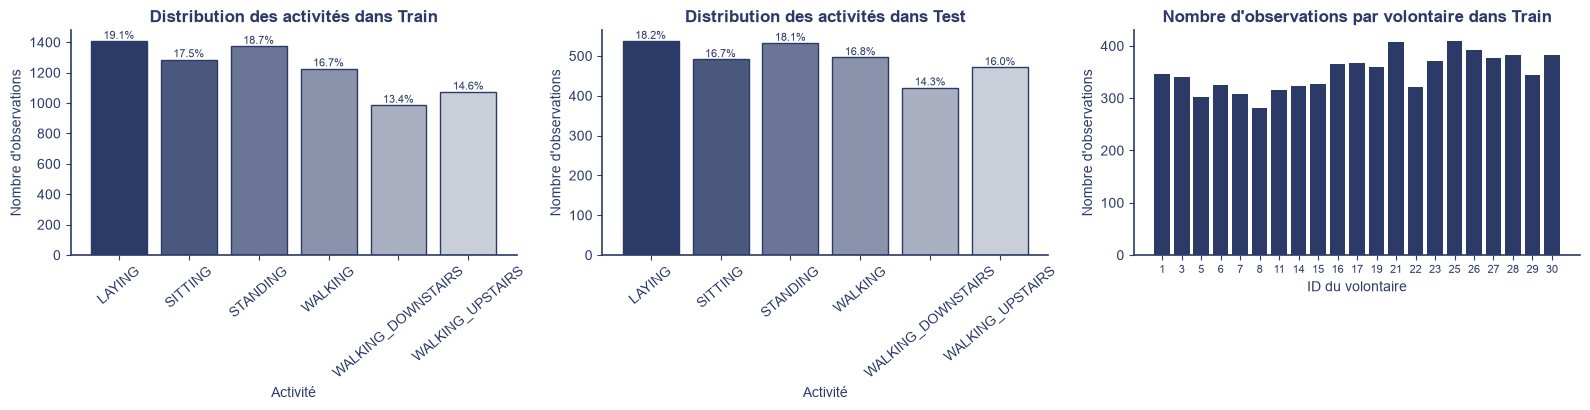

In [9]:
# Extraire les différentes classes d'activités sans répétition, puis les trier par ordre alphabétique
classes = sorted(train_df["Activity"].unique())

# 3 graphiques : distribution des activités dans Train, dans Test,
# et nombre d'observations par volontaire dans Train
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

for ax, (name, df) in zip(axes[:2], [("Train", train_df), ("Test", test_df)]):
    # Nombre d'observations par activité, rangées dans l'ordre des classes
    counts = df["Activity"].value_counts().reindex(classes)
    ax.bar(classes, counts.values, color=teintes(len(classes)), edgecolor=BLEU)
    ax.set_title(f"Distribution des activités dans {name}")
    ax.set_xlabel("Activité"); ax.set_ylabel("Nombre d'observations")
    ax.tick_params(axis="x", labelrotation=40)
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v / len(df):.1%}", ha="center", va="bottom", fontsize=8)

# Nombre d'observations par volontaire (identifiant = colonne "subject")
per_volunteer = train_df["subject"].value_counts().sort_index()
axes[2].bar(per_volunteer.index.astype(str), per_volunteer.values, color=BLEU)
axes[2].set_title("Nombre d'observations par volontaire dans Train")
axes[2].set_xlabel("ID du volontaire"); axes[2].set_ylabel("Nombre d'observations")
axes[2].tick_params(axis="x", labelsize=8)

plt.tight_layout(); plt.show()


**Remarques** : Les classes sont à peu près équilibrées. Aucune classe n'est rare ni dominante : la répartition idéale serait 16,7 % chacune.

Les proportions sont très proches entre train et test (par exemple LAYING 19,1 % contre 18,2 %, WALKING_DOWNSTAIRS 13,4 % contre 14,3 %). Les classes les plus et les moins fréquentes sont les mêmes dans les deux fichiers, et les écarts restent inférieurs à 1 point. La distribution observée à l'entraînement est donc représentative de celle du test.

**Conséquence pour les métriques** : comme le déséquilibre est modéré, l'accuracy reste interprétable (un modèle qui prédit toujours LAYING n'obtiendrait qu'environ 19 %) et elle sera proche du F1 macro. Le F1 macro reste néanmoins plus informatif, parce qu'il donne le même poids à chaque classe, y compris aux moins fréquentes, et que le F1 par classe permet de repérer les activités difficiles (typiquement SITTING et STANDING), ce que l'accuracy globale masque. On utilisera donc les deux métriques, en s'appuyant sur le F1 macro et le F1 par classe pour comparer les modèles.

### 3.3 Statistiques descriptives


In [10]:
stats = train_df[feature_cols].describe().loc[["mean", "std", "min", "max"]]

pd.set_option("display.max_columns", None)    
display(stats.round(3))

# Résumé sur les 561 variables
print("moyennes     : de", stats.loc["mean"].min().round(3), "à", stats.loc["mean"].max().round(3))
print("écart-types  : de", stats.loc["std"].min().round(3), "à", stats.loc["std"].max().round(3))
print("minimum      :", stats.loc["min"].min().round(3), "| maximum :", stats.loc["max"].max().round(3))


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,tBodyAcc-max()-Y,tBodyAcc-max()-Z,tBodyAcc-min()-X,tBodyAcc-min()-Y,tBodyAcc-min()-Z,tBodyAcc-sma(),tBodyAcc-energy()-X,tBodyAcc-energy()-Y,tBodyAcc-energy()-Z,tBodyAcc-iqr()-X,tBodyAcc-iqr()-Y,tBodyAcc-iqr()-Z,tBodyAcc-entropy()-X,tBodyAcc-entropy()-Y,tBodyAcc-entropy()-Z,"tBodyAcc-arCoeff()-X,1","tBodyAcc-arCoeff()-X,2","tBodyAcc-arCoeff()-X,3","tBodyAcc-arCoeff()-X,4","tBodyAcc-arCoeff()-Y,1","tBodyAcc-arCoeff()-Y,2","tBodyAcc-arCoeff()-Y,3","tBodyAcc-arCoeff()-Y,4","tBodyAcc-arCoeff()-Z,1","tBodyAcc-arCoeff()-Z,2","tBodyAcc-arCoeff()-Z,3","tBodyAcc-arCoeff()-Z,4","tBodyAcc-correlation()-X,Y","tBodyAcc-correlation()-X,Z","tBodyAcc-correlation()-Y,Z",tGravityAcc-mean()-X,tGravityAcc-mean()-Y,tGravityAcc-mean()-Z,tGravityAcc-std()-X,tGravityAcc-std()-Y,tGravityAcc-std()-Z,tGravityAcc-mad()-X,tGravityAcc-mad()-Y,tGravityAcc-mad()-Z,tGravityAcc-max()-X,tGravityAcc-max()-Y,tGravityAcc-max()-Z,tGravityAcc-min()-X,tGravityAcc-min()-Y,tGravityAcc-min()-Z,tGravityAcc-sma(),tGravityAcc-energy()-X,tGravityAcc-energy()-Y,tGravityAcc-energy()-Z,tGravityAcc-iqr()-X,tGravityAcc-iqr()-Y,tGravityAcc-iqr()-Z,tGravityAcc-entropy()-X,tGravityAcc-entropy()-Y,tGravityAcc-entropy()-Z,"tGravityAcc-arCoeff()-X,1","tGravityAcc-arCoeff()-X,2","tGravityAcc-arCoeff()-X,3","tGravityAcc-arCoeff()-X,4","tGravityAcc-arCoeff()-Y,1","tGravityAcc-arCoeff()-Y,2","tGravityAcc-arCoeff()-Y,3","tGravityAcc-arCoeff()-Y,4","tGravityAcc-arCoeff()-Z,1","tGravityAcc-arCoeff()-Z,2","tGravityAcc-arCoeff()-Z,3","tGravityAcc-arCoeff()-Z,4","tGravityAcc-correlation()-X,Y","tGravityAcc-correlation()-X,Z","tGravityAcc-correlation()-Y,Z",tBodyAccJerk-mean()-X,tBodyAccJerk-mean()-Y,tBodyAccJerk-mean()-Z,tBodyAccJerk-std()-X,tBodyAccJerk-std()-Y,tBodyAccJerk-std()-Z,tBodyAccJerk-mad()-X,tBodyAccJerk-mad()-Y,tBodyAccJerk-mad()-Z,tBodyAccJerk-max()-X,tBodyAccJerk-max()-Y,tBodyAccJerk-max()-Z,tBodyAccJerk-min()-X,tBodyAccJerk-min()-Y,tBodyAccJerk-min()-Z,tBodyAccJerk-sma(),tBodyAccJerk-energy()-X,tBodyAccJerk-energy()-Y,tBodyAccJerk-energy()-Z,tBodyAccJerk-iqr()-X,tBodyAccJerk-iqr()-Y,tBodyAccJerk-iqr()-Z,tBodyAccJerk-entropy()-X,tBodyAccJerk-entropy()-Y,tBodyAccJerk-entropy()-Z,"tBodyAccJerk-arCoeff()-X,1","tBodyAccJerk-arCoeff()-X,2","tBodyAccJerk-arCoeff()-X,3","tBodyAccJerk-arCoeff()-X,4","tBodyAccJerk-arCoeff()-Y,1","tBodyAccJerk-arCoeff()-Y,2","tBodyAccJerk-arCoeff()-Y,3","tBodyAccJerk-arCoeff()-Y,4","tBodyAccJerk-arCoeff()-Z,1","tBodyAccJerk-arCoeff()-Z,2","tBodyAccJerk-arCoeff()-Z,3","tBodyAccJerk-arCoeff()-Z,4","tBodyAccJerk-correlation()-X,Y","tBodyAccJerk-correlation()-X,Z","tBodyAccJerk-correlation()-Y,Z",tBodyGyro-mean()-X,tBodyGyro-mean()-Y,tBodyGyro-mean()-Z,tBodyGyro-std()-X,tBodyGyro-std()-Y,tBodyGyro-std()-Z,tBodyGyro-mad()-X,tBodyGyro-mad()-Y,tBodyGyro-mad()-Z,tBodyGyro-max()-X,tBodyGyro-max()-Y,tBodyGyro-max()-Z,tBodyGyro-min()-X,tBodyGyro-min()-Y,tBodyGyro-min()-Z,tBodyGyro-sma(),tBodyGyro-energy()-X,tBodyGyro-energy()-Y,tBodyGyro-energy()-Z,tBodyGyro-iqr()-X,tBodyGyro-iqr()-Y,tBodyGyro-iqr()-Z,tBodyGyro-entropy()-X,tBodyGyro-entropy()-Y,tBodyGyro-entropy()-Z,"tBodyGyro-arCoeff()-X,1","tBodyGyro-arCoeff()-X,2","tBodyGyro-arCoeff()-X,3","tBodyGyro-arCoeff()-X,4","tBodyGyro-arCoeff()-Y,1","tBodyGyro-arCoeff()-Y,2","tBodyGyro-arCoeff()-Y,3","tBodyGyro-arCoeff()-Y,4","tBodyGyro-arCoeff()-Z,1","tBodyGyro-arCoeff()-Z,2","tBodyGyro-arCoeff()-Z,3","tBodyGyro-arCoeff()-Z,4","tBodyGyro-correlation()-X,Y","tBodyGyro-correlation()-X,Z","tBodyGyro-correlation()-Y,Z",tBodyGyroJerk-mean()-X,tBodyGyroJerk-mean()-Y,tBodyGyroJerk-mean()-Z,tBodyGyroJerk-std()-X,tBodyGyroJerk-std()-Y,tBodyGyroJerk-std()-Z,tBodyGyroJerk-mad()-X,tBodyGyroJerk-mad()-Y,tBodyGyroJerk-mad()-Z,tBodyGyroJerk-max()-X,tBodyGyroJerk-max()-Y,tBodyGyroJerk-max()-Z,tBodyGyroJerk-min()-X,tBodyGyroJerk-min()-Y,tBodyGyroJerk-min()-Z,tBodyGyroJ

moyennes     : de -0.984 à 0.83
écart-types  : de 0.041 à 0.752
minimum      : -1.0 | maximum : 1.0


**Remarques** : Les variables sont déjà **mises à l'échelle** par les auteurs du jeu de données : sur les 561 variables, les valeurs sont toutes comprises dans l'intervalle [-1, 1].

Elles ne sont en revanche **pas centrées et réduites**.  certaines variables sont très concentrées (écart-type d'environ 0,04), d'autres très dispersées (écart-type d'environ 0,5). Une même plage [-1, 1] ne donne donc pas la même dispersion d'une variable à l'autre.

**Pourquoi cela compte pour l'optimisation** : quand les variables ont des échelles différentes, la surface de la perte est très étirée dans certaines directions : c'est une **ravine** (mauvais conditionnement). Le gradient pointe alors surtout vers les côtés de la ravine plutôt que vers le minimum. Avec un pas d'apprentissage assez grand pour avancer dans la direction plate, la descente oscille d'un bord à l'autre ; avec un pas assez petit pour être stable, elle progresse très lentement. Une même valeur du pas ne convient pas à toutes les variables. Centrer et réduire chaque variable rend la surface plus régulière : le gradient pointe plus directement vers le minimum, le pas peut être plus grand, et la convergence est plus rapide et plus stable. **On standardisera donc les variables (moyenne et écart-type calculés sur le train uniquement) à l'étape preprocessing**.

findfont: Failed to find font weight semibold for Arial, now using 700.


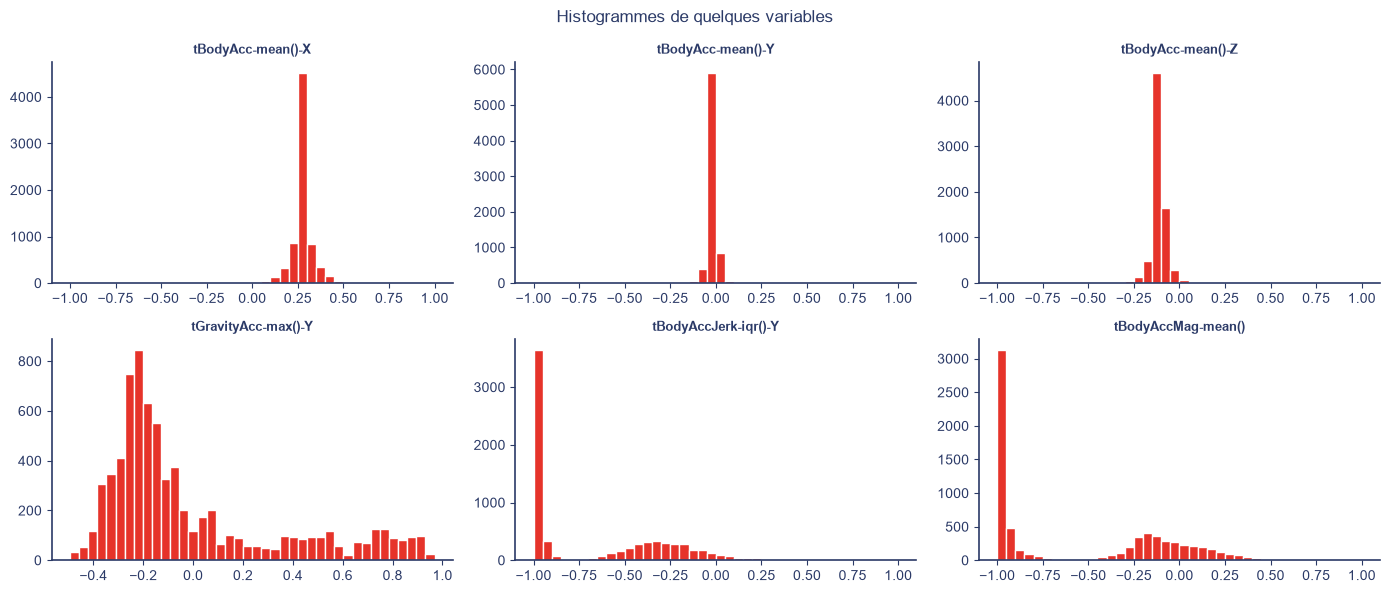

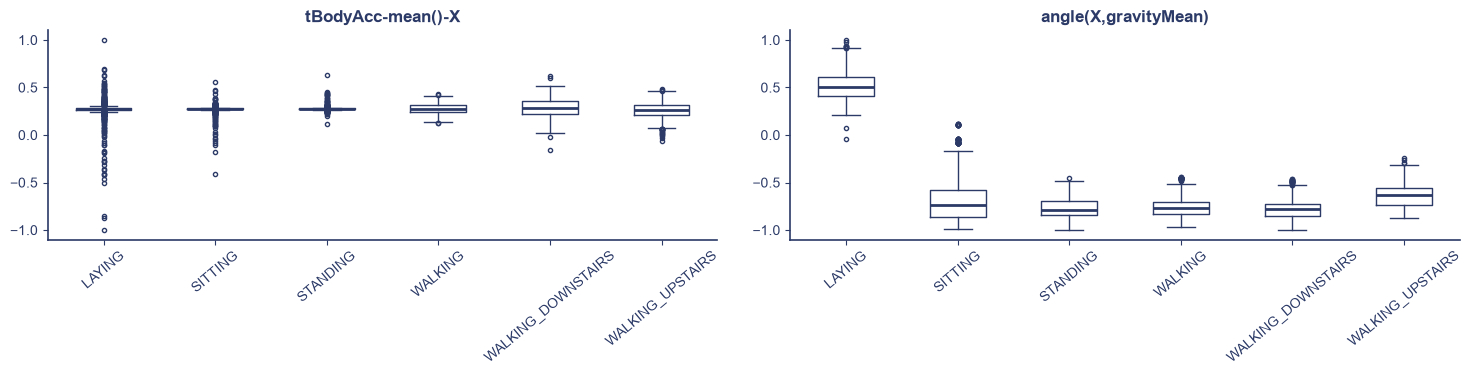

In [11]:
cols_h = [feature_cols[i] for i in [0, 1, 2, 50, 100, 200]]
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, c in zip(axes.ravel(), cols_h):
    ax.hist(train_df[c], bins=40, color=ROUGE, edgecolor=BLANC)
    ax.set_title(c[:35], fontsize=9)
plt.suptitle("Histogrammes de quelques variables"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for ax, c in zip(axes, [feature_cols[0], feature_cols[-3]]):
    train_df.boxplot(column=c, by="Activity", ax=ax, rot=40, grid=False,
                 color=dict(boxes=BLEU, whiskers=BLEU, medians=BLEU, caps=BLEU),
                 flierprops=dict(marker="o", markeredgecolor=BLEU, markerfacecolor="none", markersize=3),
                 medianprops=dict(linewidth=2, color=BLEU))
    ax.set_title(c[:40]); ax.set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()


rq: angle(X,gravityMean): Sur chaque fenêtre, on calcule le vecteur gravité moyen (ses trois composantes), puis l’angle entre l’axe X du téléphone et ce vecteur. Cela dit comment le téléphone est orienté par rapport à la verticale. Couché, l’orientation est très différente de celle des autres postures, d’où la séparation de LAYING.

### 3.4 Corrélations entre variables


paires avec |corrélation| > 0.95 : 2281 sur 157080 (1.5%)


C:\Users\ReMarkt\AppData\Local\Temp\ipykernel_340\3403029921.py:77: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


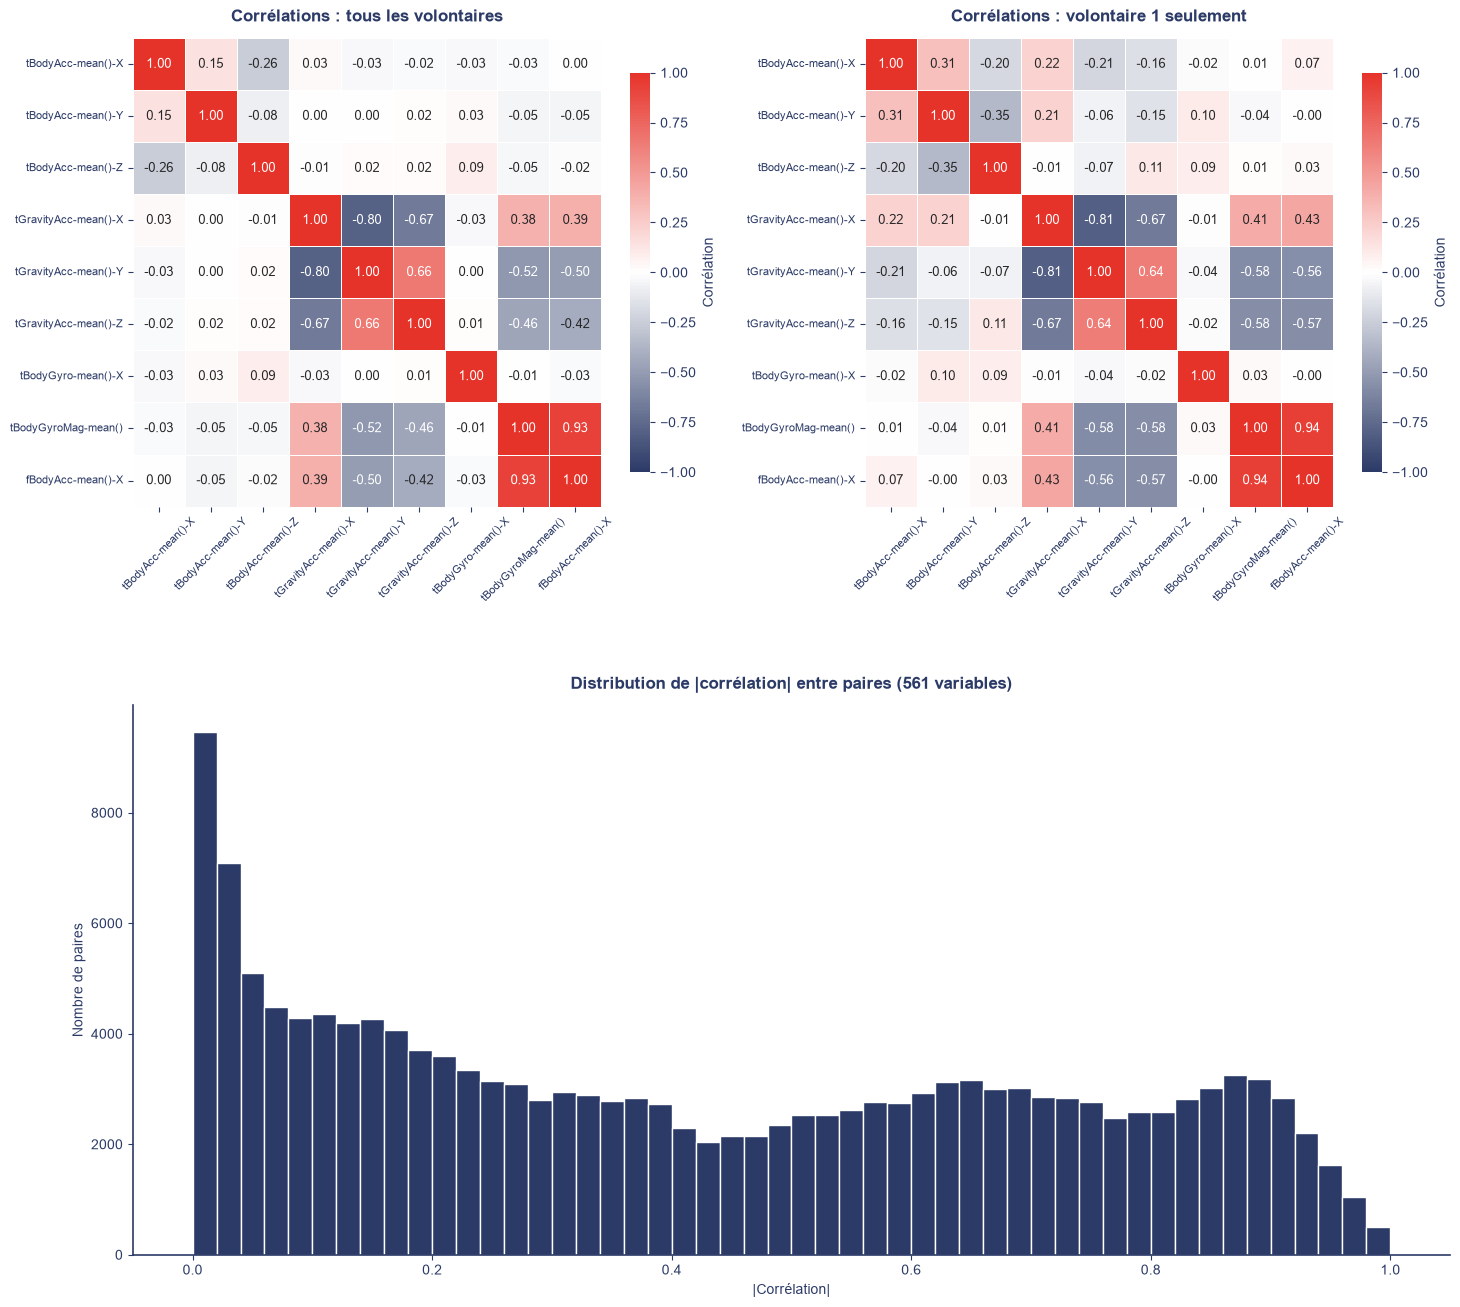

In [12]:
# Volontaire pris comme exemple
target_subject = 1
subj_df = train_df[train_df["subject"] == target_subject]

# Quelques variables représentatives
sample_features = [
    "tBodyAcc-mean()-X", "tBodyAcc-mean()-Y", "tBodyAcc-mean()-Z",
    "tGravityAcc-mean()-X", "tGravityAcc-mean()-Y", "tGravityAcc-mean()-Z",
    "tBodyGyro-mean()-X", "tBodyGyroMag-mean()", "fBodyAcc-mean()-X",
]

corr_all = train_df[sample_features].corr()
corr_subj = subj_df[sample_features].corr()

# Corrélations entre toutes les paires de variables
corr_full = train_df[feature_cols].corr().to_numpy()
iu = np.triu_indices_from(corr_full, k=1)
high = np.abs(corr_full[iu]) > 0.95

print(
    f"paires avec |corrélation| > 0.95 : "
    f"{high.sum()} sur {len(iu[0])} ({high.mean():.1%})"
)

# plots 
fig = plt.figure(figsize=(17, 16))

gs = fig.add_gridspec(
    2, 2,
    height_ratios=[1, 1.1],
    hspace=0.35,
    wspace=0.25
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

for ax, corr, titre in [
    (ax1, corr_all, "Corrélations : tous les volontaires"),
    (ax2, corr_subj, f"Corrélations : volontaire {target_subject} seulement")
]:
    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap=CMAP_DIV,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        linecolor=BLANC,
        cbar_kws={"label": "Corrélation", "shrink": 0.8},
        annot_kws={"size": 9},
        ax=ax
    )

    ax.set_title(titre, pad=12)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)

# Histogramme
ax3.hist(
    np.abs(corr_full[iu]),
    bins=50,
    color=BLEU,
    edgecolor=BLANC
)

ax3.set_title(
    "Distribution de |corrélation| entre paires (561 variables)",
    pad=12
)
ax3.set_xlabel("|Corrélation|")
ax3.set_ylabel("Nombre de paires")

plt.tight_layout()
plt.show()


### 3.5 Encodage de la cible et préparation des tableaux
Les réseaux travaillent avec des nombres : on associe un entier de 0 à 5 à chaque activité (ordre alphabétique). La colonne `subject` n'est **pas** une entrée du modèle : on la garde à part, car elle servira au découpage de la partie suivante.

In [13]:
class_to_idx = {c: i for i, c in enumerate(classes)}
print(class_to_idx)

X_all = train_df[feature_cols].to_numpy(dtype=np.float32)
y_all = train_df["Activity"].map(class_to_idx).to_numpy()
subject_all = train_df["subject"].to_numpy()

print("X_all :", X_all.shape, X_all.dtype, "| y_all :", y_all.shape, y_all.dtype)
print("exemples par classe :", np.bincount(y_all))


{'LAYING': 0, 'SITTING': 1, 'STANDING': 2, 'WALKING': 3, 'WALKING_DOWNSTAIRS': 4, 'WALKING_UPSTAIRS': 5}
X_all : (7352, 561) float32 | y_all : (7352,) int64
exemples par classe : [1407 1286 1374 1226  986 1073]


 rq: La colonne `subject` sert uniquement à **découper** les données en train et validation par volontaires entiers.

### Bilan du prétraitement
- **Échelle** : les 561 variables sont déjà comprises dans [-1, 1], mais ne sont ni centrées ni réduites. On les **standardise**, avec la moyenne et l'écart-type calculés sur le train uniquement, pour améliorer le conditionnement de l'optimisation.
- **Encodage** : la cible `Activity` est transformée en entiers de 0 à 5 ( LAYING 0, SITTING 1, STANDING 2, WALKING 3, WALKING_DOWNSTAIRS 4, WALKING_UPSTAIRS 5), au type `int64` attendu par `CrossEntropyLoss`. Les entrées sont en `float32`.
- **Colonnes** : aucune valeur manquante, aucune ligne dupliquée, aucune variable non numérique. `subject` est exclue des entrées et gardée pour le découpage ; `Activity` est la cible.
- **Redondance** : forte (beaucoup de paires de variables avec |corrélation| > 0,9) mais on conserve toutes les variables : le réseau s'en accommode et la régularisation limitera le surapprentissage. Une sélection de variables est envisagée en ouverture.
- **Classes** : à peu près équilibrées (de 13,4 % à 19,1 % dans le train, 7352 fenêtres au total), proportions proches du test. On suivra donc l'accuracy et le F1 macro, ainsi que le F1 par classe.

# découpage par volontaires et régression logistique de référence


In [14]:
import json
from matplotlib.colors import LinearSegmentedColormap
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

appliquer_charte()        

def set_seed(seed=0):
    np.random.seed(seed)

set_seed(0)


### load data & encodage de la cible
comme on a fait à l'exploration

In [15]:
DATA_DIR = "../data/raw_har_data"
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df  = pd.read_csv(f"{DATA_DIR}/test.csv")

feature_cols = [c for c in train_df.columns if c not in ("subject", "Activity")]
classes = sorted(train_df["Activity"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

X_all = train_df[feature_cols].to_numpy(dtype=np.float32)
y_all = train_df["Activity"].map(class_to_idx).to_numpy()
subject_all = train_df["subject"].to_numpy()

print("X_all :", X_all.shape, "| y_all :", y_all.shape, "| volontaires :", len(np.unique(subject_all)))


X_all : (7352, 561) | y_all : (7352,) | volontaires : 21



## Découpage apprentissage / validation par volontaires

Au test, les volontaires sont **nouveaux** : la validation doit imiter cette situation. On réserve donc 5 volontaires entiers de `train.csv`.


In [16]:
subjects = np.sort(np.unique(subject_all))
rng = np.random.default_rng(0)
val_subjects = np.sort(rng.choice(subjects, size=5, replace=False))
is_val = np.isin(subject_all, val_subjects)

X_train, y_train = X_all[~is_val], y_all[~is_val]
X_val,   y_val   = X_all[is_val],  y_all[is_val]

print("volontaires de validation :", val_subjects.tolist())
print("volontaires d'apprentissage :", len(subjects) - len(val_subjects))
print(f"apprentissage : {len(y_train)} fenêtres | validation : {len(y_val)} fenêtres ({len(y_val) / len(y_all):.1%})")
print("fenêtres par volontaire de validation :")
print(pd.Series(subject_all[is_val]).value_counts().sort_index().to_string())

# On sauvegarde le découpage pour que les notebooks suivants utilisent exactement les mêmes volontaires
with open("../data/split_volontaires.json", "w") as f:
    json.dump({"val_subjects": [int(s) for s in val_subjects], "seed": 0}, f)


volontaires de validation : [8, 11, 16, 19, 23]
volontaires d'apprentissage : 16
apprentissage : 5657 fenêtres | validation : 1695 fenêtres (23.1%)
fenêtres par volontaire de validation :
8     281
11    316
16    366
19    360
23    372


Chaque volontaire a fait les six activités ; la validation doit donc contenir toutes les classes, dans des proportions voisines de celles de l'apprentissage.

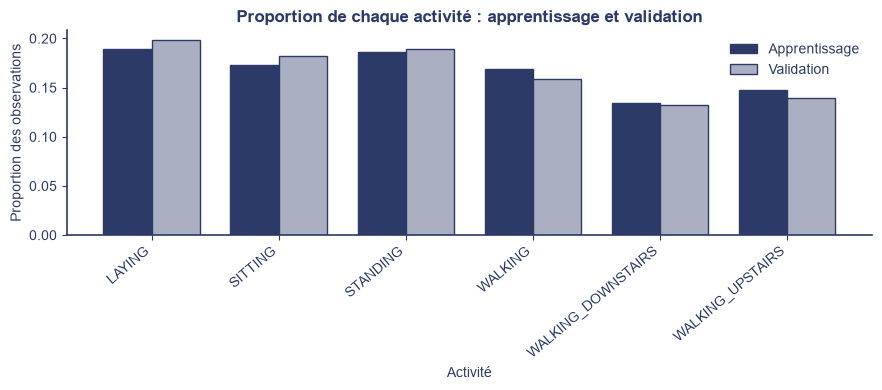

nombre d'exemples par classe en validation : [336 309 320 269 224 237]


In [17]:
prop_train = np.bincount(y_train, minlength=len(classes)) / len(y_train)
prop_val   = np.bincount(y_val,   minlength=len(classes)) / len(y_val)

x = np.arange(len(classes)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w / 2, prop_train, w, label="Apprentissage", color=BLEU, edgecolor=BLEU)
ax.bar(x + w / 2, prop_val,   w, label="Validation", color=teintes(2, 0.6)[1], edgecolor=BLEU)
ax.set_xticks(x); ax.set_xticklabels(classes, rotation=40, ha="right")
ax.set_title("Proportion de chaque activité : apprentissage et validation")
ax.set_xlabel("Activité"); ax.set_ylabel("Proportion des observations"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
print("nombre d'exemples par classe en validation :", np.bincount(y_val, minlength=len(classes)))


### Standardisation
standardisation **sur l'apprentissage uniquement**, puis appliqués à la validation (et plus tard au test).
-> to prevent data leakage

In [18]:
mu = X_train.mean(axis=0)
sd = X_train.std(axis=0)
sd[sd == 0] = 1.0                      # division par zéro (FI)

def standardise(X):
    return ((X - mu) / sd).astype(np.float32)

X_train_s, X_val_s = standardise(X_train), standardise(X_val)
X_test_s = standardise(test_df[feature_cols].to_numpy(dtype=np.float32))
y_test = test_df["Activity"].map(class_to_idx).to_numpy()

print("apprentissage : moyenne des moyennes =", X_train_s.mean(axis=0).mean().round(4), "| écart-type moyen =", X_train_s.std(axis=0).mean().round(4))
print("validation    : moyenne des moyennes =", X_val_s.mean(axis=0).mean().round(4), "| écart-type moyen =", X_val_s.std(axis=0).mean().round(4))


apprentissage : moyenne des moyennes = 0.0 | écart-type moyen = 1.0
validation    : moyenne des moyennes = 0.0716 | écart-type moyen = 1.2092


In [19]:
# Sauvegarde des données standardisées
import os

DOSSIER = "../data/processed_har_data"
os.makedirs(DOSSIER, exist_ok=True)

def vers_csv(X_s, y, subject, nom):
    df = pd.DataFrame(X_s, columns=feature_cols)
    df["subject"] = subject
    df["Activity"] = np.array(classes)[y]          
    df.to_csv(f"{DOSSIER}/{nom}.csv", index=False, float_format="%.9g")
    print(f"{nom}.csv sauvegardé :", os.path.getsize(f"{DOSSIER}/{nom}.csv") // 1024, "Ko")

vers_csv(X_train_s, y_train, subject_all[~is_val], "train_processed")
vers_csv(X_val_s,   y_val,   subject_all[is_val],  "val_processed")
vers_csv(X_test_s,  y_test,  test_df["subject"].to_numpy(), "test_processed")

# On garde aussi mu et sd (calculés sur le train), utiles pour standardiser de nouvelles données
pd.DataFrame({"variable": feature_cols, "mean": mu, "std": sd}).to_csv(
    f"{DOSSIER}/standardisation_stats.csv", index=False)


train_processed.csv sauvegardé : 38259 Ko
val_processed.csv sauvegardé : 11448 Ko
test_processed.csv sauvegardé : 19951 Ko



On entraîne la même régression logistique deux fois :
-  avec un découpage par volontaires
- avec un découpage aléatoire de lignes, de même proportion de validation.

Chaque modèle est évalué sur sa propre validation.

In [20]:
def fit_logreg(X, y):
    mu_, sd_ = X.mean(axis=0), X.std(axis=0); sd_[sd_ == 0] = 1.0
    clf = LogisticRegression(max_iter=500).fit((X - mu_) / sd_, y)
    return clf, mu_, sd_

def eval_logreg(clf, mu_, sd_, X, y):
    pred = clf.predict((X - mu_) / sd_)
    return accuracy_score(y, pred), f1_score(y, pred, average="macro"), pred

#  découpage par volontaires
clf_sub, mu_sub, sd_sub = fit_logreg(X_train, y_train)
acc_sub, f1_sub, pred_sub = eval_logreg(clf_sub, mu_sub, sd_sub, X_val, y_val)

#  découpage aléatoire de lignes
train_idx, val_idx = train_test_split(np.arange(len(X_all)), test_size=is_val.mean(), stratify=y_all, random_state=0)
clf_rnd, mu_rnd, sd_rnd = fit_logreg(X_all[train_idx], y_all[train_idx])
acc_rnd, f1_rnd, _ = eval_logreg(clf_rnd, mu_rnd, sd_rnd, X_all[val_idx], y_all[val_idx])

comparaison = pd.DataFrame({"accuracy (validation)": [acc_rnd, acc_sub], "F1 macro (validation)": [f1_rnd, f1_sub]},
                           index=["lignes aléatoires", "volontaires entiers"])
display(comparaison.round(4))


,accuracy (validation),F1 macro (validation)
lignes aléatoires,0.9870,0.9879
volontaires entiers,0.9168,0.9187


**Remarques** Le découpage aléatoire donne de meilleurs scores (accuracy 0,987 ; F1 macro 0,988) que le découpage par volontaires (0,917 ; 0,919), mais ce gain est artificiel. Les fenêtres se chevauchent de 50 % et un même volontaire apparaît dans l’apprentissage et la validation : Avec un découpage aléatoire, la validation contient presque des copies de fenêtres du train. Le modèle les « reconnaît » plus qu’il ne généralise, et le score est gonflé. C’est la fuite de données dont on a parlé.
l'écart de 7 points est la taille de lafuite 

Le découpage par volontaires évalue la généralisation à de nouvelles personnes, ce qui correspond au test final. Nous retenons donc ce dernier comme référence, avec une accuracy de validation d’environ 0,92 -> estimation plus honnéte.

## Référence : la régression logistique

In [21]:
print(f"Régression logistique (validation par volontaires) : accuracy = {acc_sub:.4f} | F1 macro = {f1_sub:.4f}\n")
print(classification_report(y_val, pred_sub, target_names=classes, digits=3))


Régression logistique (validation par volontaires) : accuracy = 0.9168 | F1 macro = 0.9187

                    precision    recall  f1-score   support

            LAYING      0.973     0.976     0.975       336
           SITTING      0.819     0.926     0.869       309
          STANDING      0.921     0.806     0.860       320
           WALKING      0.871     0.981     0.923       269
WALKING_DOWNSTAIRS      0.967     0.924     0.945       224
  WALKING_UPSTAIRS      0.995     0.890     0.940       237

          accuracy                          0.917      1695
         macro avg      0.925     0.917     0.919      1695
      weighted avg      0.922     0.917     0.917      1695



### 2.2 Matrice de confusion sur la validation
Chaque ligne est une activité réelle, chaque colonne l'activité prédite : la diagonale contient les bonnes réponses. Les valeurs sont en proportion de chaque ligne.

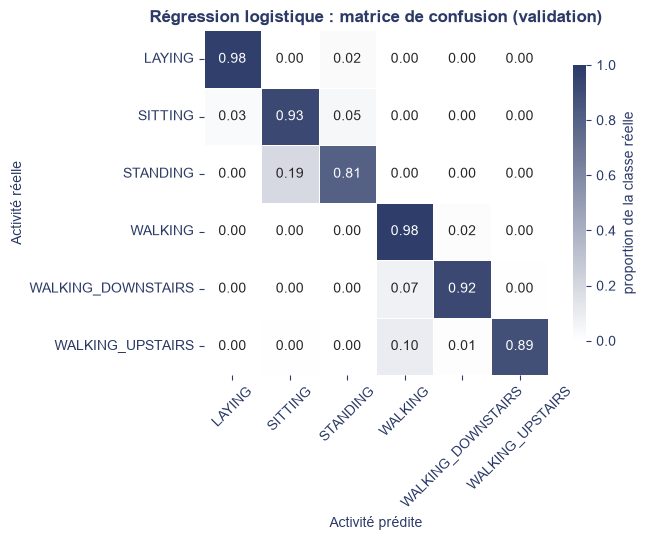

In [22]:
cm = confusion_matrix(y_val, pred_sub)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
cmap_bleu = LinearSegmentedColormap.from_list("charte_bleu", [BLANC, BLEU])

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap=cmap_bleu, vmin=0, vmax=1, square=True,
            linewidths=0.5, linecolor=BLANC, xticklabels=classes, yticklabels=classes,
            cbar_kws={"label": "proportion de la classe réelle", "shrink": 0.8}, ax=ax)
ax.set_title("Régression logistique : matrice de confusion (validation)")
ax.set_xlabel("Activité prédite"); ax.set_ylabel("Activité réelle")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout(); plt.show()


les confusions sont entre:
- STANDING et SITTING
- WALKING ET LA MARCHE EN ESCLAIER
LAYING est presque parfaite

# un MLP à une couche cachée


## 1. Imports et configuration

In [23]:
import os, time, random, warnings
from IPython.display import display

import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
#charte graphique
from charte_graphique import appliquer_charte, BLEU, ROUGE, BLANC, GRIS, teintes
appliquer_charte()
warnings.filterwarnings("ignore")

#pour les cartes de chaleur à val positives
cmap_bleu = LinearSegmentedColormap.from_list("charte_bleu", [BLANC, BLEU])

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(0)
torch.set_num_threads(1)     
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device, "| torch", torch.__version__)


Device : cpu | torch 2.15.0+cpu


## load processed data

In [24]:
DATA_DIR = os.environ.get("HAR_DIR", "../data/processed_har_data")

train_df = pd.read_csv(f"{DATA_DIR}/train_processed.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val_processed.csv")

feature_cols = [c for c in train_df.columns if c not in ("subject", "Activity")]
classes = sorted(train_df["Activity"].unique())            
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)

X_train_s = train_df[feature_cols].to_numpy(dtype=np.float32)
y_train   = train_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
X_val_s   = val_df[feature_cols].to_numpy(dtype=np.float32)
y_val     = val_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)

print("classes :", class_to_idx)
print("X_train_s :", X_train_s.shape, X_train_s.dtype, "| y_train :", y_train.shape, y_train.dtype)
print("X_val_s   :", X_val_s.shape, "| y_val :", y_val.shape)
print("volontaires train :", train_df["subject"].nunique(), "| volontaires validation :", val_df["subject"].nunique())


classes : {'LAYING': 0, 'SITTING': 1, 'STANDING': 2, 'WALKING': 3, 'WALKING_DOWNSTAIRS': 4, 'WALKING_UPSTAIRS': 5}
X_train_s : (5657, 561) float32 | y_train : (5657,) int64
X_val_s   : (1695, 561) | y_val : (1695,)
volontaires train : 16 | volontaires validation : 5


In [25]:
#mini batchs pour l'entraînement et la validation
def make_loader(X, y, batch_size=128, shuffle=False, seed=0):
    g = torch.Generator(); g.manual_seed(seed) #décider l'ordre dans lesquels les exps sont mélangés avec la meme graine on obtient à chaque fois le même ordre à chaque exécution -> reproductibilité
    #former les paires (entrée X , étiquettes y)
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=g if shuffle else None)

train_loader      = make_loader(X_train_s, y_train, 128, shuffle=True, seed=0)
train_eval_loader = make_loader(X_train_s, y_train, 512)     #mesurer la perte sur tout le train sans mettre a jour les poids, sans mélange , L’ordre n’a aucune importance pour mesurer
val_loader        = make_loader(X_val_s,   y_val,   512)


##  MLP à 1 couche cachée


In [26]:
EPOCHS   = 150   
PATIENCE = 10   
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}

class MLP_ONE_HIDDEN_LAYER(nn.Module):
    
    def __init__(self, in_dim, hidden=64, n_classes=6, act="relu"):
        super().__init__()
        self.hidden_layer = nn.Linear(in_dim, hidden)
        self.act = ACTIVATIONS[act]()
        self.out_layer = nn.Linear(hidden, n_classes)

    def forward(self, x):
        return self.out_layer(self.act(self.hidden_layer(x)))
#compter le nombre de paramètres du modèle qu'on peut ajuster
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

in_dim = X_train_s.shape[1]
model = MLP_ONE_HIDDEN_LAYER(in_dim, hidden=64, n_classes=n_classes, act="relu")
print(model)
print("Nombre de paramètres :", count_params(model), "= (561*64 + 64) + (64*6 + 6)")


MLP_ONE_HIDDEN_LAYER(
  (hidden_layer): Linear(in_features=561, out_features=64, bias=True)
  (act): ReLU()
  (out_layer): Linear(in_features=64, out_features=6, bias=True)
)
Nombre de paramètres : 36358 = (561*64 + 64) + (64*6 + 6)


##  Vérifications avant d'entraîner

In [27]:
#fonction de perte
criterion = nn.CrossEntropyLoss()
print("perte attendue pour un réseau qui ne sait rien : ln(6) =", round(float(np.log(n_classes)), 3))


perte attendue pour un réseau qui ne sait rien : ln(6) = 1.792


In [28]:
# Perte initiale -> loss attendue ≈ ln(6) ≈ 1.792
set_seed(0)
m0 = MLP_ONE_HIDDEN_LAYER(in_dim, 64, n_classes, "relu").to(device)
m0.eval()
with torch.no_grad():
    logits = m0(torch.from_numpy(X_train_s).to(device))
    perte_initiale = criterion(logits, torch.from_numpy(y_train).to(device)).item()

perte_theorique = float(np.log(n_classes))
print(f"Perte initiale = {perte_initiale:.3f}  (attendu ≈ ln(6) = {perte_theorique:.3f})")
print(f"Écart absolu = {abs(perte_initiale - perte_theorique):.3f}")


Perte initiale = 1.841  (attendu ≈ ln(6) = 1.792)
Écart absolu = 0.049


écart à seulement 0,003 de la perte attendue -> bonne signe 
cette écart provient de l'intialisation aléatoire de début des poids 

Petit lot : loss 1.785 -> 0.00174 | accuracy sur le lot = 1.00


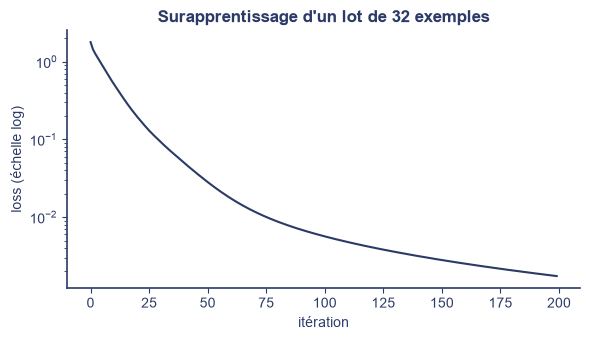

In [29]:
# OVERFITTING Le réseau doit pouvoir surapprendre un tout petit lot (32 exemples)
set_seed(0)
m1 = MLP_ONE_HIDDEN_LAYER(in_dim, 64, n_classes, "relu").to(device)
opt1 = torch.optim.Adam(m1.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()
xb, yb = next(iter(make_loader(X_train_s, y_train, 32, shuffle=True, seed=0)))
xb, yb = xb.to(device), yb.to(device)

losses = []
for step in range(200):
    opt1.zero_grad()
    loss = crit(m1(xb), yb)
    loss.backward() #gradient 
    opt1.step()
    losses.append(loss.item())

acc_lot = (m1(xb).argmax(1) == yb).float().mean().item()
print(f"Petit lot : loss {losses[0]:.3f} -> {losses[-1]:.5f} | accuracy sur le lot = {acc_lot:.2f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(losses, color=BLEU)
ax.set_title("Surapprentissage d'un lot de 32 exemples")
ax.set_xlabel("itération"); ax.set_ylabel("loss (échelle log)")
plt.tight_layout(); plt.show()


le réseau a mémorisé bien le petit lot donc le code de train fonctionne bien. 
perte au départ = 1,785 -> perte après 200 iterations = 0,00174
accuracy = 100 %

##  Fonctions d'entraînement et d'évaluation

In [30]:
#choix de l'optimiseur
def make_optimizer(name, params, lr):
    if name == "sgd":  return torch.optim.SGD(params, lr=lr)
    if name == "sgdm": return torch.optim.SGD(params, lr=lr, momentum=0.9)
    if name == "adam": return torch.optim.Adam(params, lr=lr)
    raise ValueError(name)


In [31]:
#entrainement
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total, ys, ps = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb)
        ps.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": total / len(y), "acc": accuracy_score(y, p), "f1": f1_score(y, p, average="macro")}


In [32]:
#evaluate en mesurant les performance sans modifier les poids 
import copy

@torch.no_grad()
def evaluate(model, loader):
    criterion = nn.CrossEntropyLoss()
    model.eval()
    total, ys, ps = 0.0, [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        total += criterion(out, yb).item() * len(yb)
        ps.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return {"loss": total / len(y), "acc": accuracy_score(y, p),
            "f1": f1_score(y, p, average="macro"), "pred": p}

def fit(model, optimizer, epochs, patience=None):
    criterion = nn.CrossEntropyLoss()
    hist = []
    best_loss, best_state, best_ep, attente = float("inf"), None, 0, 0
    for ep in range(1, epochs + 1):
        tr = train_epoch(model, train_loader, criterion, optimizer)
        va = evaluate(model, val_loader)
        hist.append({"epoch": ep,
                     "train_loss": tr["loss"], "train_acc": tr["acc"], "train_f1": tr["f1"],
                     "val_loss": va["loss"],   "val_acc": va["acc"],   "val_f1": va["f1"]})
        if va["loss"] < best_loss:                                   # nouvelle meilleure époque
            best_loss, best_ep, attente = va["loss"], ep, 0
            if patience: best_state = copy.deepcopy(model.state_dict())
        else:
            attente += 1
        if patience and attente >= patience:                         # plus d'amélioration : on arrête
            break
    if patience and best_state is not None:
        model.load_state_dict(best_state)                            # on restaure les meilleurs poids
    return pd.DataFrame(hist), best_ep


In [33]:
def run(act, opt, lr, epochs, hidden=64, seed=0, patience=None):
    global train_loader
    train_loader = make_loader(X_train_s, y_train, 128, shuffle=True, seed=seed)
    set_seed(seed)
    model = MLP_ONE_HIDDEN_LAYER(in_dim, hidden, n_classes, act).to(device)
    optimizer = make_optimizer(opt, model.parameters(), lr)
    t0 = time.time()
    hist, best_ep = fit(model, optimizer, epochs, patience)
    return {"model": model, "hist": hist, "best_epoch": best_ep, "time": time.time() - t0}

## Réglage du pas d'apprentissage

LR range test : on fait croître le pas d'apprentissage de façon exponentielle pendant quelques itérations et on regarde la loss.

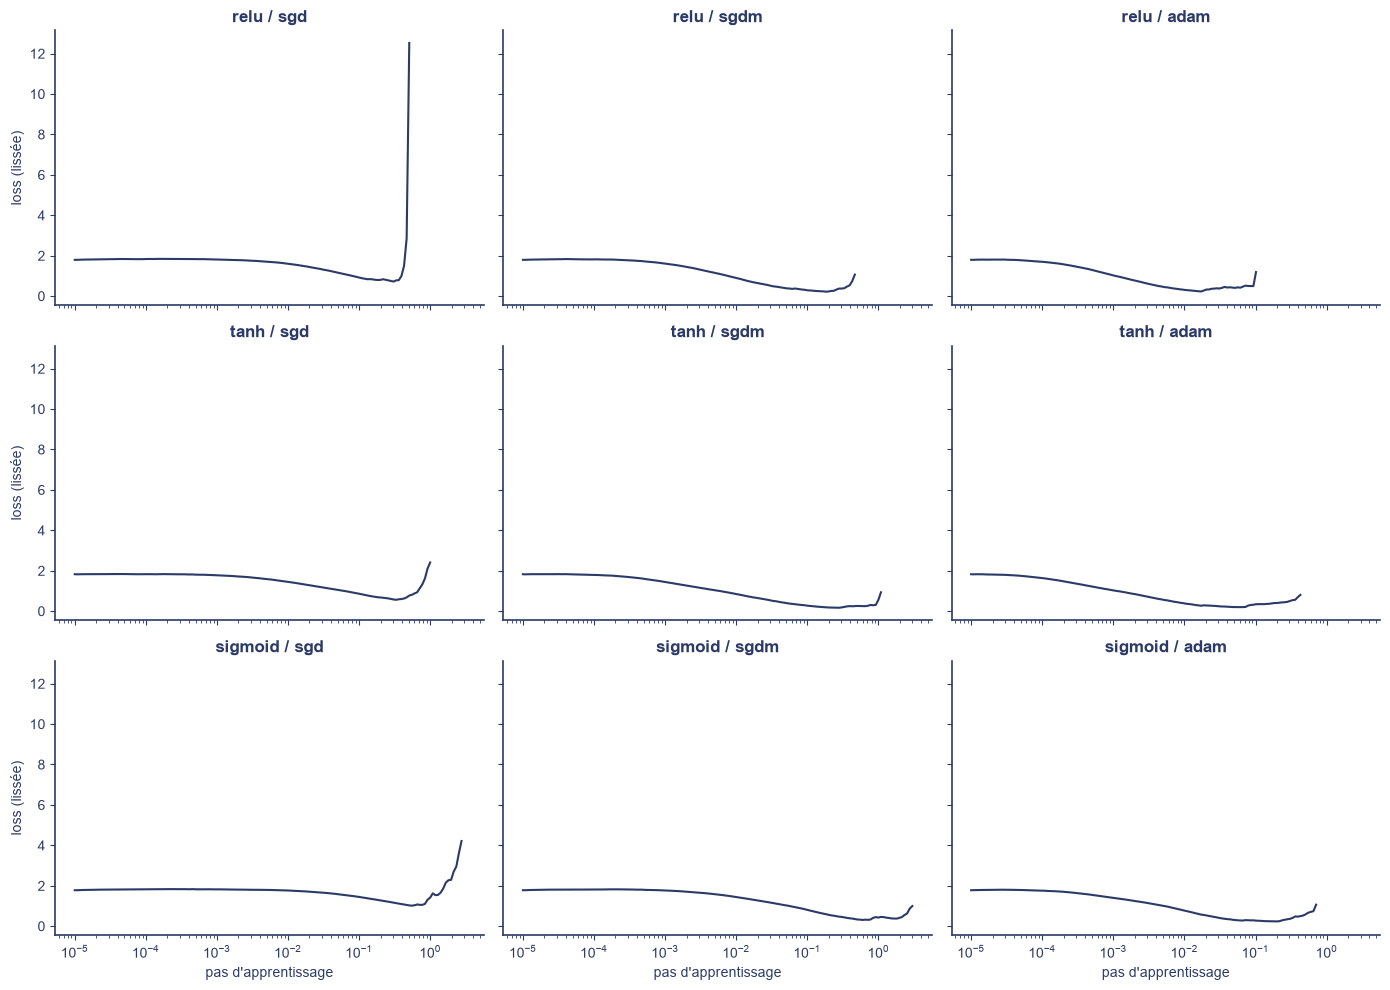

In [34]:
def lr_range_test(opt_name, act="relu", lr_min=1e-5, lr_max=3.0, n_iter=150):
    set_seed(0)
    model = MLP_ONE_HIDDEN_LAYER(in_dim, 64, n_classes, act).to(device)
    optimizer = make_optimizer(opt_name, model.parameters(), lr_min)
    crit = nn.CrossEntropyLoss()
    lrs = np.geomspace(lr_min, lr_max, n_iter)
    loader = make_loader(X_train_s, y_train, 128, shuffle=True, seed=0)
    it = iter(loader)
    smooth, out = None, []
    for i, lr in enumerate(lrs):
        for g in optimizer.param_groups:
            g["lr"] = lr
        try:
            xb, yb = next(it)
        except StopIteration:
            it = iter(loader); xb, yb = next(it)
        xb, yb = xb.to(device), yb.to(device)
        model.train()
        optimizer.zero_grad()
        loss = crit(model(xb), yb)
        loss.backward()
        optimizer.step()
        l = loss.item()
        smooth = l if smooth is None else 0.9 * smooth + 0.1 * l     # lissage de la courbe
        out.append(smooth)
        if i > 10 and (smooth > 4 * min(out) or not np.isfinite(smooth)):
            break                                                    # divergence : on arrête
    return lrs[:len(out)], np.array(out)

OPTS = ["sgd", "sgdm", "adam"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10), sharex=True, sharey=True)
for i, act in enumerate(["relu", "tanh", "sigmoid"]):
    for j, o in enumerate(OPTS):
        lrs, ls = lr_range_test(o, act=act)
        axes[i, j].semilogx(lrs, ls, color=BLEU)
        axes[i, j].set_title(f"{act} / {o}")
for ax in axes[2]:
    ax.set_xlabel("pas d'apprentissage")
for ax in axes[:, 0]:
    ax.set_ylabel("loss (lissée)")
plt.tight_layout(); plt.show()


Le LR range test, réalisé pour chacun des 9 couples (activation, optimiseur), montre que le pas utile dépend de l’activation et de l’optimiseur : Adam fonctionne entre 10⁻³ et 10⁻¹ pour les trois activations, tandis que SGD demande des pas de l’ordre de 0,1 à 0,3 pour ReLU et tanh et nettement plus grands pour sigmoid, dont les gradients sont plus faibles

Le range test donne un ordre de grandeur, pas une valeur exacte. On affine donc avec une **petite grille logarithmique**, évaluée sur la validation (F1 macro), **pour chaque couple (activation, optimiseur)** : le bon pas dépend des deux.

In [35]:
LR_GRID = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1, 1.0]
ACT_LIST = ["relu", "tanh", "sigmoid"]

GRID_EPOCHS   = 60   
GRID_PATIENCE = 5
GRID_FILE = "../results/etape4_grille_lr.csv"
os.makedirs("../results", exist_ok=True)

if os.path.exists(GRID_FILE):                   
    grid = pd.read_csv(GRID_FILE)
    print("grille rechargée depuis", GRID_FILE)
else:
    grid_rows = []
    for act in ACT_LIST:
        for o in OPTS:
            for lr in LR_GRID:
                r = run(act, o, lr, GRID_EPOCHS, patience=GRID_PATIENCE)
                best = r["hist"].iloc[r["best_epoch"] - 1]
                grid_rows.append({"act": act, "opt": o, "lr": lr,
                                  "val_f1": best["val_f1"], "val_loss": best["val_loss"]})
            print(f"{act} / {o} terminé")
    grid = pd.DataFrame(grid_rows)
    grid.to_csv(GRID_FILE, index=False)

# Meilleur pas pour chaque couple (activation, optimiseur)
best_lr = grid.loc[grid.groupby(["act", "opt"])["val_f1"].idxmax()].set_index(["act", "opt"])["lr"]
print("Pas d'apprentissage retenus :")
display(best_lr.to_frame("lr"))


grille rechargée depuis ../results/etape4_grille_lr.csv
Pas d'apprentissage retenus :


lr
act     opt         
relu    adam  0.0010
        sgd   0.0100
        sgdm  0.0300
sigmoid adam  0.0100
        sgd   1.0000
        sgdm  0.3000
tanh    adam  0.0003
        sgd   0.3000
        sgdm  0.0100

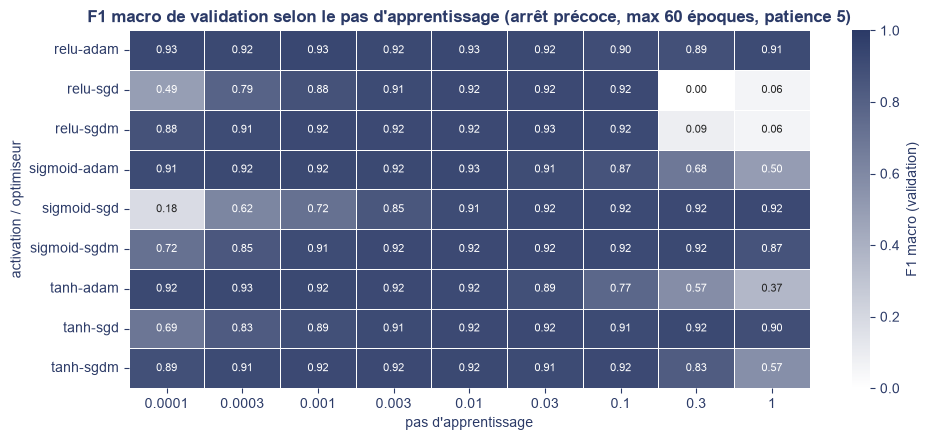

In [36]:
# Carte de chaleur : F1 macro de validation pour chaque (activation, optimiseur) et chaque pas
piv = grid.pivot_table(index=["act", "opt"], columns="lr", values="val_f1")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(piv, annot=True, fmt=".2f", cmap=cmap_bleu, vmin=0, vmax=1, linewidths=0.5, linecolor=BLANC,
            annot_kws={"size": 8}, cbar_kws={"label": "F1 macro (validation)"}, ax=ax)
ax.set_xticklabels([f"{v:g}" for v in piv.columns], rotation=0)
ax.set_title(f"F1 macro de validation selon le pas d'apprentissage (arrêt précoce, max {GRID_EPOCHS} époques, patience {GRID_PATIENCE})")
ax.set_xlabel("pas d'apprentissage"); ax.set_ylabel("activation / optimiseur")
plt.tight_layout(); plt.show()


- La grille de pas d'apprentissage montre, pour chaque couple (activation, optimiseur), un large plateau où le F1 macro de validation atteint 0,92 à 0,93 (plages avec F1 ≥ 0,91 : Adam environ 10⁻⁴ à 10⁻² ; SGD environ 3×10⁻³ à 0,1–0,3, jusqu'à 1 pour sigmoid ; SGD avec momentum environ 3×10⁻⁴ à 0,1–0,3).
- Un pas trop petit conduit à un sous-apprentissage : avec SGD à 10⁻⁴, le F1 tombe à 0,18 (sigmoid), 0,49 (ReLU) et 0,69 (tanh), le réseau n'ayant pas convergé dans les 60 époques de la grille.
- Un pas trop grand conduit à une divergence : ReLU avec SGD à 0,3 donne un F1 de 0,00 (0,06 à 1) et ReLU avec momentum 0,09 (0,06 à 1) ; Adam se dégrade aussi avec de grands pas (tanh : 0,57 à 0,3 et 0,37 à 1 ; sigmoid : 0,68 et 0,50).
- Le pas utile est plus petit pour Adam que pour SGD, et plus grand pour sigmoid que pour ReLU avec SGD (SGD avec momentum compris).

-> le choix de l'optimiseur et de l'activation change peu le F1 : le pas d'apprentissage compte beaucoup plus.

## Activations × optimiseurs (Question 2.2)

In [37]:
results = {}
for act in ACT_LIST:
    for o in OPTS:
        results[(act, o)] = run(act, o, best_lr[(act, o)], EPOCHS, patience=PATIENCE)

rows = []
for (act, o), r in results.items():
    h = r["hist"]; best = h.iloc[r["best_epoch"] - 1]
    rows.append({"activation": act, "optimiseur": o, "lr": best_lr[(act, o)],
                 "train F1": best["train_f1"], "val acc": best["val_acc"], "val F1": best["val_f1"],
                 "écart F1 (train - val)": best["train_f1"] - best["val_f1"],
                 "meilleure époque": r["best_epoch"], "époques faites": len(h),
                 "temps (s)": r["time"]})
tab = pd.DataFrame(rows)

display(tab.round(4))
display(tab.pivot(index="activation", columns="optimiseur", values="val F1").round(4))


,activation,optimiseur,lr,train F1,val acc,val F1,écart F1 (train - val),meilleure époque,époques faites,temps (s)
0,relu,sgd,0.0100,0.9784,0.9204,0.9207,0.0577,36,46,14.2227
1,relu,sgdm,0.0300,0.9867,0.9245,0.9262,0.0605,8,18,5.7339
2,relu,adam,0.0010,0.9840,0.9292,0.9304,0.0536,8,18,6.3343
3,tanh,sgd,0.3000,0.9649,0.9215,0.9219,0.0430,5,15,4.6862
4,tanh,sgdm,0.0100,0.9774,0.9221,0.9225,0.0549,5,15,4.9143
5,tanh,adam,0.0003,0.9808,0.9257,0.9257,0.0551,14,24,7.8024
6,sigmoid,sgd,1.0000,0.9628,0.9186,0.9189,0.0439,5,15,2.4277
7,sigmoid,sgdm,0.3000,0.9618,0.9245,0.9244,0.0374,4,14,2.2161
8,sigmoid,adam,0.0100,0.9860,0.9245,0.9259,0.0601,8,18,5.1720


optimiseur,adam,sgd,sgdm
activation,,,
relu,0.9304,0.9207,0.9262
sigmoid,0.9259,0.9189,0.9244
tanh,0.9257,0.9219,0.9225


- Le MLP à une couche cachée fait à peine mieux que la régression logistique (F1 macro de validation 0,9187) : le meilleur résultat est ReLU avec Adam (0,9304, soit +0,012), et aucune des neuf configurations ne reste en dessous de la référence (minimum 0,9189). Gain très faible avec une seule couche cachée.

- Les F1 des 9 configurations sont compris entre 0,919 et 0,930 : avec une seule graine, ces écarts ne permettent pas de désigner une activation ou un optimiseur gagnant.

- La meilleure époque est comprise entre 4 et 8 pour sept configurations ; elle vaut 14 pour tanh avec Adam et 36 pour ReLU avec SGD, qui converge le plus lentement.
- Accuracy et F1 macro sont presque identiques, puisque les classes sont équilibrées.

- Toutes les configurations surapprennent : le F1 d'entraînement vaut 0,962 à 0,987, soit un écart de 0,037 à 0,061 avec la validation. Le early stopping réduit cet écart (0,06 à 0,09 sans arrêt précoce, 40 époques), mais ne le supprime pas.

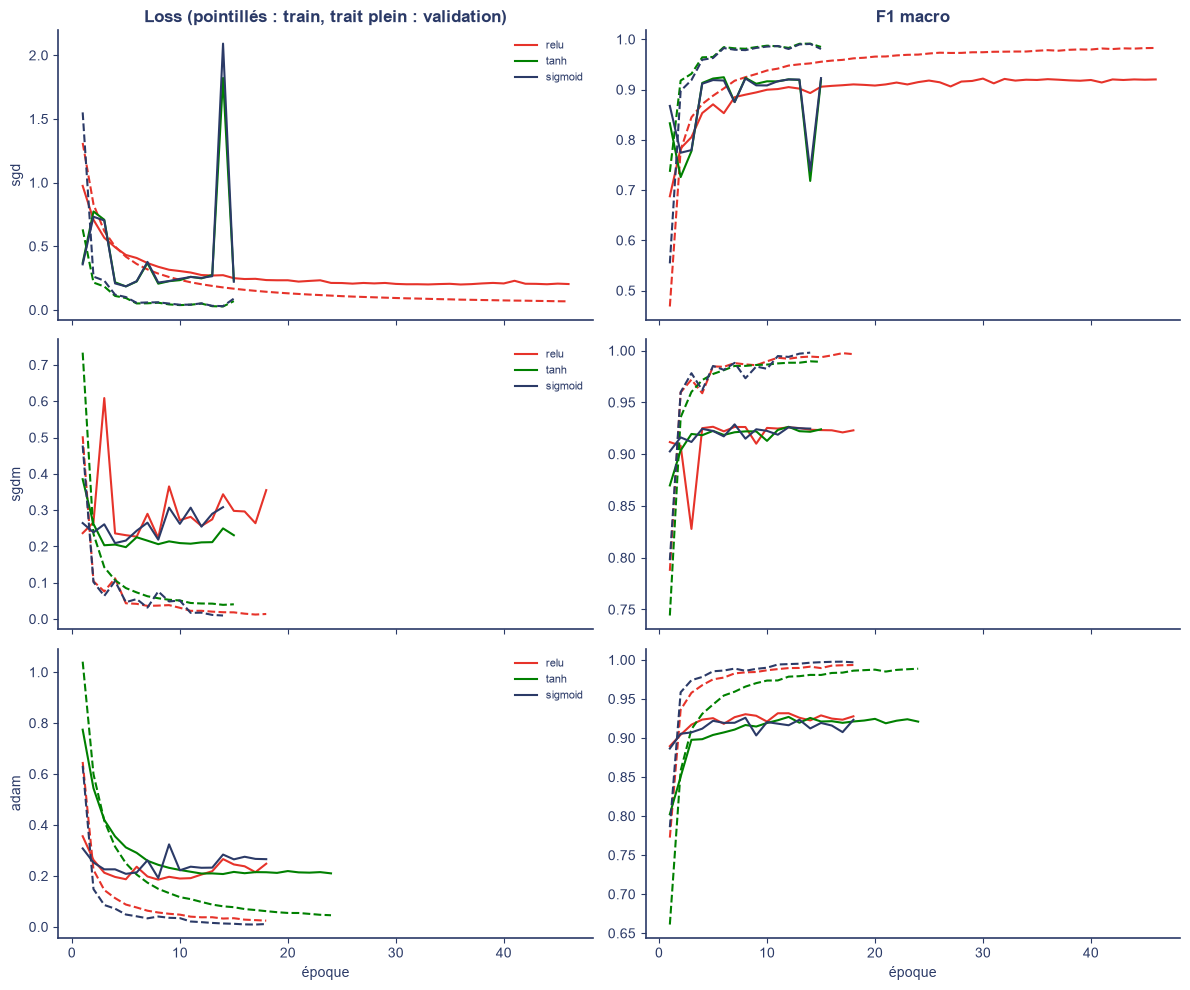

In [38]:
# Courbes d'apprentissage : une ligne par optimiseur, une couleur par activation
couleurs = {"sigmoid": BLEU, "relu": ROUGE, "tanh":  "#008000"}     # bleu, rouge, gris moyen

fig, axes = plt.subplots(3, 2, figsize=(12, 10), sharex=True)
for i, o in enumerate(OPTS):
    for act in ACT_LIST:
        h = results[(act, o)]["hist"]
        for j, m in enumerate(["loss", "f1"]):
            axes[i, j].plot(h["epoch"], h[f"train_{m}"], "--", color=couleurs[act])
            axes[i, j].plot(h["epoch"], h[f"val_{m}"], "-", color=couleurs[act], label=act)
    axes[i, 0].set_ylabel(o)
    axes[i, 0].legend(frameon=False, fontsize=8)
axes[0, 0].set_title("Loss (pointillés : train, trait plein : validation)")
axes[0, 1].set_title("F1 macro")
axes[2, 0].set_xlabel("époque"); axes[2, 1].set_xlabel("époque")
plt.tight_layout(); plt.show()


## Conclusions
- **Vitesse de convergence** : avec le early stopping, la meilleure époque est comprise entre 4 et 14 pour 8/9 configurations (ReLU avec SGD est plus lent : 36). SGD+momentum atteint son minimum le plus tôt (4 à 8), Adam un peu plus tard (8 à 14), SGD varie le plus (5 à 36). Le F1 de validation dépasse 0,90 dès les 1 à 5 premières époques, sauf pour ReLU avec SGD (vers l'époque 10).

- **Stabilité** : Adam donne les courbes les plus régulières : la loss de validation passe par un minimum (≈ 0,2) vers les époques 6 à 10, puis remonte légèrement pour ReLU et sigmoid (0,25 à 0,3) pendant que le F1 reste autour de 0,92 à 0,93 ; tanh décroît plus lentement et se stabilise vers 0,21. Avec SGD, ReLU est lisse (loss ≈ 0,2 à 0,3), alors que tanh et sigmoid ont un pic isolé à l'époque 14 (loss ≈ 1,8 à 2,1, F1 ≈ 0,72) dont ils se remettent à l'époque suivante. Avec momentum, la loss de validation est plus bruitée : ReLU passe par un pic à l'époque 3 (loss 0,61, F1 0,83) puis oscille entre 0,22 et 0,37, sigmoid oscille entre 0,21 et 0,31, tanh est la plus lisse (≈ 0,2 à 0,25). Dans tous les cas, le F1 de validation reste stable (≈ 0,92) : la loss, plus sensible, est le premier indicateur de surapprentissage.

- **Écart train / validation** : le F1 d'entraînement vaut 0,962 à 0,987 contre 0,919 à 0,930 en validation, soit un écart de 0,037 à 0,061 : les réseaux surapprennent. La loss de validation atteint son minimum tôt puis stagne ou remonte pendant que celle d'entraînement tend vers 0.

- **Effet de l'activation** : pas d'activation dominante. ReLU est la meilleure avec Adam (0,9304) et momentum (0,9262), tanh avec SGD (0,9219), et sigmoid la moins bonne avec SGD (0,9189). À optimiseur fixé, l'écart entre activations ne dépasse pas 0,005.

- **Sensibilité au pas** : la carte de chaleur montre, pour chaque couple, un plateau où le F1 vaut 0,92 à 0,93. Un pas trop petit donne un sous-apprentissage, un pas trop grand une divergence. Le pas utile est plus petit pour Adam que pour SGD, et plus grand pour sigmoid que pour ReLU avec SGD.

- **Comparaison avec la référence** : la régression logistique atteint 0,9187. Le meilleur MLP (ReLU/Adam, 0,9304) la dépasse de 0,012, et aucune des neuf configurations ne reste en dessous : le MLP à une couche cachée n'apporte pas de gain net.


## Analyse par classe

In [39]:
best_key = tab.loc[tab["val F1"].idxmax(), ["activation", "optimiseur"]].tolist()
best_key = tuple(best_key)
best = results[best_key]
pred_best = evaluate(best["model"], val_loader)["pred"]
print("Meilleure combinaison (1 graine) :", best_key, "| pas =", best_lr[best_key])
print(classification_report(y_val, pred_best, target_names=classes, digits=3))

print("Répartition des classes en validation :")
print(pd.Series(y_val).map(dict(enumerate(classes))).value_counts(normalize=True).round(3).to_string())


Meilleure combinaison (1 graine) : ('relu', 'adam') | pas = 0.001
                    precision    recall  f1-score   support

            LAYING      0.974     1.000     0.987       336
           SITTING      0.843     0.922     0.881       309
          STANDING      0.947     0.834     0.887       320
           WALKING      0.884     0.967     0.924       269
WALKING_DOWNSTAIRS      0.968     0.933     0.950       224
  WALKING_UPSTAIRS      0.991     0.920     0.954       237

          accuracy                          0.929      1695
         macro avg      0.934     0.929     0.930      1695
      weighted avg      0.932     0.929     0.929      1695

Répartition des classes en validation :
LAYING                0.198
STANDING              0.189
SITTING               0.182
WALKING               0.159
WALKING_UPSTAIRS      0.140
WALKING_DOWNSTAIRS    0.132


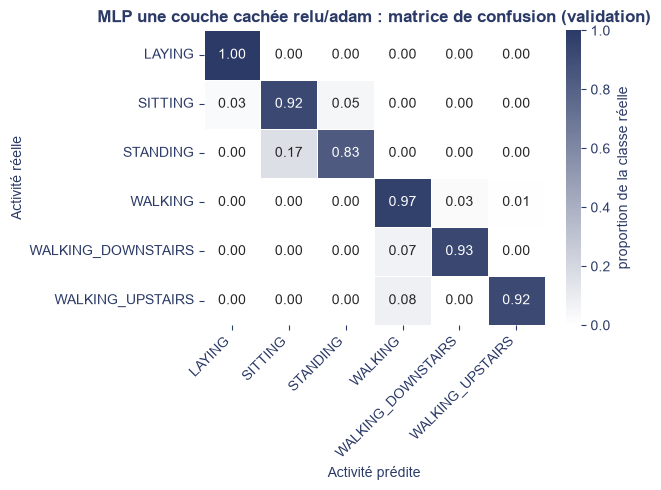

In [ ]:
# Matrice de confusion du meilleur MLP 
cm = confusion_matrix(y_val, pred_best, labels=range(n_classes))
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cmn, annot=True, fmt=".2f", cmap=cmap_bleu, vmin=0, vmax=1, xticklabels=classes, yticklabels=classes,
            linewidths=0.5, linecolor=BLANC, cbar_kws={"label": "proportion de la classe réelle"}, ax=ax)
ax.set_title(f"MLP une couche cachée {best_key[0]}/{best_key[1]} : matrice de confusion (validation)")
ax.set_xlabel("Activité prédite"); ax.set_ylabel("Activité réelle")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()


Sur la validation, l'accuracy (0,929) et le F1 macro (0,930) du meilleur MLP (ReLU/Adam) sont quasi identiques. C'est normal : les classes sont assez équilibrées, donc l'accuracy n'est pas dominée par une classe majoritaire, et le F1 macro, qui donne le même poids aux six activités, évolue de la même façon. Les deux mesures auraient divergé avec des classes très déséquilibrées.

Le F1 par classe est en revanche plus informatif : LAYING est quasi parfaite (0,987), les trois marches se situent entre 0,92 et 0,95, tandis que SITTING (0,881) et STANDING (0,887) sont les plus difficiles, avec 17 % des fenêtres "STANDING" classées "SITTING" (et 5 % des "SITTING" classées "STANDING").

Par rapport à la régression logistique, le MLP améliore surtout STANDING (+0,027), puis WALKING_UPSTAIRS (+0,014) et SITTING (+0,012) ; WALKING est inchangé (+0,001).

# Variabilité des résultats

In [41]:
SEEDS = [0, 1, 2, 3, 4]

configs = [
    {"nom": "tanh / SGD",              "act": "tanh", "opt": "sgd",  "lr": best_lr[("tanh", "sgd")]},
    {"nom": "tanh / Adam",             "act": "tanh", "opt": "adam", "lr": best_lr[("tanh", "adam")]},
    {"nom": f"relu / Adam (lr {best_lr[('relu', 'adam')]:g})", "act": "relu", "opt": "adam", "lr": best_lr[("relu", "adam")]},
]

seed_results = {}
for cfg in configs:
    runs = []
    for s in SEEDS:
        train_loader = make_loader(X_train_s, y_train, 128, shuffle=True, seed=s)
        r = run(cfg["act"], cfg["opt"], cfg["lr"], EPOCHS, seed=s, patience=PATIENCE)
        best = r["hist"].iloc[r["best_epoch"] - 1]
        runs.append({"graine": s, "val_f1": best["val_f1"], "val_acc": best["val_acc"],
                     "train_f1": best["train_f1"], "meilleure_epoque": r["best_epoch"]})
    seed_results[cfg["nom"]] = pd.DataFrame(runs)
    print(cfg["nom"], "terminé")

lignes = []
for cfg in configs:
    d = seed_results[cfg["nom"]]
    lignes.append({"configuration": cfg["nom"], "lr": cfg["lr"],
                   "val F1 (moy ± std)": f"{d['val_f1'].mean():.4f} ± {d['val_f1'].std():.4f}",
                   "val acc (moy ± std)": f"{d['val_acc'].mean():.4f} ± {d['val_acc'].std():.4f}",
                   "écart F1 train - val": round((d["train_f1"] - d["val_f1"]).mean(), 4),
                   "meilleure époque (moy)": round(d["meilleure_epoque"].mean(), 1)})
tab_seeds = pd.DataFrame(lignes)
display(tab_seeds)


tanh / SGD terminé
tanh / Adam terminé
relu / Adam (lr 0.001) terminé


,configuration,lr,val F1 (moy ± std),val acc (moy ± std),écart F1 train - val,meilleure époque (moy)
0,tanh / SGD,0.3000,0.9219 ± 0.0056,0.9215 ± 0.0056,0.0515,7.0
1,tanh / Adam,0.0003,0.9213 ± 0.0026,0.9214 ± 0.0025,0.0640,18.2
2,relu / Adam (lr 0.001),0.0010,0.9282 ± 0.0037,0.9274 ± 0.0035,0.0560,8.2


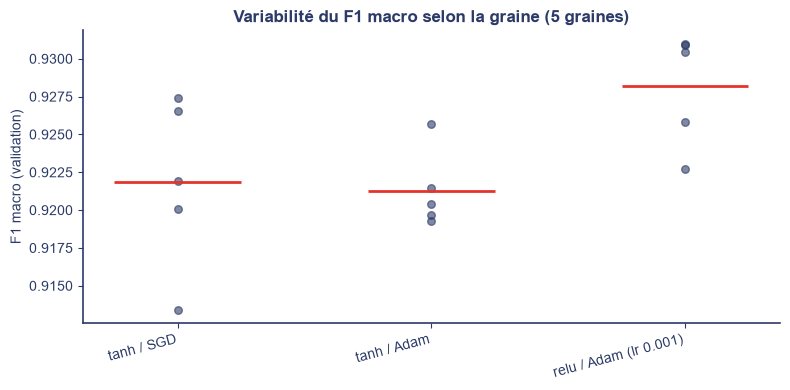

In [42]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, cfg in enumerate(configs):
    d = seed_results[cfg["nom"]]["val_f1"]
    ax.scatter([i] * len(d), d, color=BLEU, alpha=0.6, s=30)           # un point par graine
    ax.hlines(d.mean(), i - 0.25, i + 0.25, color=ROUGE, linewidth=2)  # moyenne
ax.set_xticks(range(len(configs))); ax.set_xticklabels([c["nom"] for c in configs], rotation=15, ha="right")
ax.set_ylabel("F1 macro (validation)"); ax.set_title(f"Variabilité du F1 macro selon la graine ({len(SEEDS)} graines)")
plt.tight_layout(); plt.show()


**Bilan de la variabilité**
Le classement à une graine est fragile : l'écart entre les moyennes des configurations (0,007 au maximum) est du même ordre que la dispersion entre graines (écart-type de 0,0026 à 0,0056 ; tanh/SGD va de 0,913 à 0,927 selon la graine). tanh/SGD (0,9219 ± 0,0056) et tanh/Adam (0,9213 ± 0,0026) ne se distinguent pas.

-> ReLU avec Adam et un pas de 0,001 (F1 = 0,9282 ± 0,0037) a la plus haute moyenne sur 5 graines et dépasse la régression logistique (0,9187) d'environ 2,5 écarts-types : ses 5 graines sont toutes au-dessus de la référence, alors que tanh/SGD en a une en dessous. Ses graines recoupent toutefois celles de tanh/SGD (0,923 à 0,931 contre 0,913 à 0,927) : l'avantage reste modeste.

# Courbes d'apprentissage et évaluation finale


## 1. Imports et configuration

In [43]:

from sklearn.preprocessing import StandardScaler

GRIS_LIGNE = "#8A8A8A"
cmap_bleu = sns.light_palette(BLEU, as_cmap=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)


Device : cpu


In [44]:
CONFIGS = [
    {"nom": "Version 1 : 1 couche (64), sans régularisation", "version": 1,
     "hidden": (64,), "dropout": 0.0, "norm": None, "wd": 0.0,
     "nom_cv": "1x64 : référence"},
]

# Valeurs issues de la validation croisée (Version 2, partie régularisation) : on les reporte ici pour que
# ce notebook soit indépendant (nombre d'époques = médiane des meilleures époques, 1x64 avec arrêt précoce)
CV_1X64 = {"epochs": 10, "f1_cv": 0.9252, "f1_cv_std": 0.0552}
lignes = []
for cfg in CONFIGS:
    cfg["epochs"] = CV_1X64["epochs"]
    cfg["f1_cv"] = CV_1X64["f1_cv"]
    cfg["f1_cv_std"] = CV_1X64["f1_cv_std"]
    lignes.append({"configuration": cfg["nom"], "époques (médiane CV)": cfg["epochs"],
                   "F1 validation croisée": f"{cfg['f1_cv']:.4f} ± {cfg['f1_cv_std']:.4f}"})
display(pd.DataFrame(lignes))


,configuration,époques (médiane CV),F1 validation croisée
0,"Version 1 : 1 couche (64), sans régularisation",10,0.9252 ± 0.0552


In [ ]:
DATA_DIR = os.environ.get("HAR_DIR", "../data/processed_har_data")

train_df = pd.read_csv(f"{DATA_DIR}/train_processed.csv")
val_df   = pd.read_csv(f"{DATA_DIR}/val_processed.csv")
all_df = pd.concat([train_df, val_df], ignore_index=True)

feat = [c for c in all_df.columns if c not in ("subject", "Activity")]
classes = sorted(all_df["Activity"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)

X_all = all_df[feat].to_numpy(dtype=np.float32)
y_all = all_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)
subj  = all_df["subject"].to_numpy()
in_dim = X_all.shape[1]

val_subjects = json.load(open("../data/split_volontaires.json"))["val_subjects"]
est_val = np.isin(subj, val_subjects)
X_tr, y_tr, X_va, y_va = X_all[~est_val], y_all[~est_val], X_all[est_val], y_all[est_val]
print("21 volontaires :", X_all.shape, "| courbes 5.1 : train", X_tr.shape[0], "/ val", X_va.shape[0],
      "| volontaires de validation :", val_subjects)


21 volontaires : (7352, 561) | courbes 5.1 : train 5657 / val 1695 | volontaires de validation : [8, 11, 16, 19, 23]


## 4. Modèle et fonctions d'entraînement

In [46]:
ACTIVATIONS = {"relu": nn.ReLU, "tanh": nn.Tanh, "sigmoid": nn.Sigmoid}

class MLP(nn.Module):
    """[Linear -> (BatchNorm) -> activation -> (Dropout)] x L, puis une couche de sortie linéaire."""
    def __init__(self, in_dim, hidden=(64,), n_classes=6, act="relu", dropout=0.0, norm=None):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if norm == "bn":
                layers.append(nn.BatchNorm1d(h))
            layers.append(ACTIVATIONS[act]())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            d = h
        self.features = nn.Sequential(*layers)
        self.out_layer = nn.Linear(d, n_classes)

    def forward(self, x):
        return self.out_layer(self.features(x))

def build(cfg):
    return MLP(in_dim, cfg["hidden"], n_classes, "relu", cfg["dropout"], cfg["norm"]).to(device)

def train_epoch(model, loader, criterion, optimizer):
    model.train()
    total, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(yb); n += len(yb)
    return total / n

def entrainer(cfg, X, y, epochs, seed, suivi=None):
    """Entraîne `epochs` époques (Adam 1e-3, batch 128) et garde les derniers poids.
    suivi = (X_val, y_val) : si fourni, on enregistre les courbes à chaque époque."""
    set_seed(seed)
    model = build(cfg)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=cfg["wd"])
    crit = nn.CrossEntropyLoss()
    loader = make_loader(X, y, 128, shuffle=True, seed=seed)
    if suivi is not None:
        va_loader = make_loader(*suivi, 512); tr_eval = make_loader(X, y, 512)
    hist = []
    for ep in range(1, epochs + 1):
        tr_loss = train_epoch(model, loader, crit, opt)
        if suivi is not None:
            va = evaluate(model, va_loader); tr = evaluate(model, tr_eval)
            hist.append({"epoch": ep, "train_loss": tr_loss, "val_loss": va["loss"],
                         "train_f1": tr["f1"], "val_f1": va["f1"]})
    return model, pd.DataFrame(hist)



Sur le découpage de la partie 2 (16 volontaires pour l'entraînement, 5 pour la validation), on entraîne chaque configuration **60 époques sans arrêt précoce**, avec 3 graines. 
Ces courbes servent à **comprendre** l'entraînement 

findfont: Failed to find font weight semibold for Arial, now using 700.


Version 1 : 1 couche (64), sans régularisation terminé


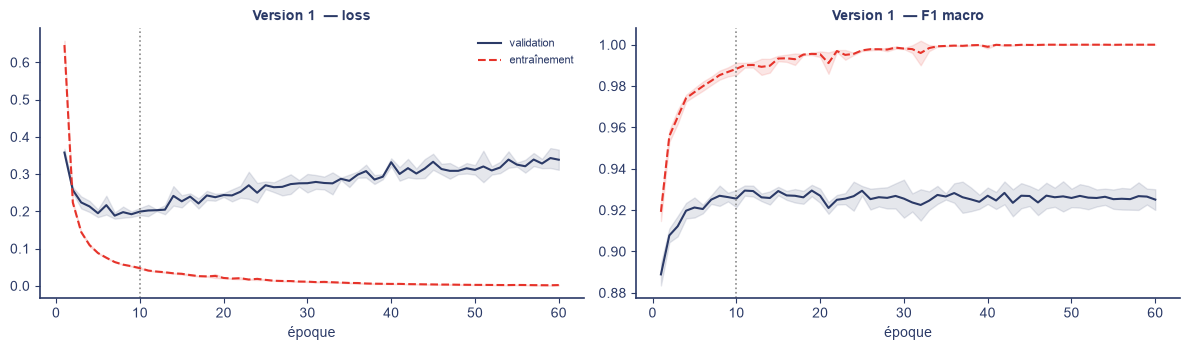

In [47]:
COURBES_EPOCHS = 60
courbes = {}
for cfg in CONFIGS:
    hs = [entrainer(cfg, X_tr, y_tr, COURBES_EPOCHS, seed=s, suivi=(X_va, y_va))[1] for s in range(3)]
    courbes[cfg["nom"]] = pd.concat(hs).groupby("epoch").agg(["mean", "std"])
    print(cfg["nom"], "terminé")

fig, ax = plt.subplots(len(CONFIGS), 2, figsize=(12, 3.6 * len(CONFIGS)), squeeze=False)
for i, cfg in enumerate(CONFIGS):
    h = courbes[cfg["nom"]]; ep = h.index
    for col, key, st, lab in [(BLEU, "val", "-", "validation"), (ROUGE, "train", "--", "entraînement")]:
        for j, m in enumerate(["loss", "f1"]):
            mu, sd = h[(f"{key}_{m}", "mean")], h[(f"{key}_{m}", "std")]
            ax[i, j].plot(ep, mu, st, color=col, label=lab)
            ax[i, j].fill_between(ep, mu - sd, mu + sd, color=col, alpha=0.12)
    for j, t in enumerate(["loss", "F1 macro"]):
        ax[i, j].axvline(cfg["epochs"], color=GRIS_LIGNE, linestyle=":", linewidth=1.2)
        ax[i, j].set_xlabel("époque"); ax[i, j].set_title(f"{cfg['nom'].split(':')[0]} — {t}", fontsize=10)
    ax[i, 0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()


**les courbes d'apprentissage montrent**

-  la loss d'entraînement tend vers 0 , alors que la loss de validation passe par un minimum (≈ 0,19 entre les époques 6 et 10) puis remonte régulièrement jusqu' à l'époque 60. Le réseau finit par mémoriser l'entraînement (F1 d'entraînement ≈ 1,00 ) sans mieux généraliser.

- Le minimum de la loss de validation (époques 6 à 10) est proche de la ligne verticale, qui marque les 10 époques choisies par la validation croisée. Le critère de la validation croisée est donc cohérent avec ces courbes.

- F1 de validation ne baisse pas quand la loss remonte. Il monte jusqu'à ≈ 0,92 à 0,93 vers l'époque 5 puis reste sur un plateau jusqu'à l'époque 60. Le réseau classe aussi bien, mais avec des probabilités de plus en plus tranchées, ce qui fait augmenter la loss : la loss est un indicateur de surapprentissage plus sensible que le F1.

- l'écart entre train et val  se creuse lentement après l'époque optimale.

- les bandes sont étroites (3 grains) : l'entraînement est stable d'une graine à l'autre. La validation oscille un peu d'une époque à l'autre , ce qui est attendu avec seulement 5 volontaires de validation.



##  Évaluation finale sur le test 


In [ ]:
CONFIRMER_TEST = True       
SEEDS_FINALES = [0, 1, 2, 3, 4]
FICHIER_TEST = "../results/test_final_v1.csv"


In [ ]:
def evaluation_finale():
    if os.path.exists(FICHIER_TEST):
        print(f"Note : {FICHIER_TEST} existe déjà, il est recalculé (graines fixées, résultats identiques).")
    test_df = pd.read_csv(f"{DATA_DIR}/test_processed.csv")            # première lecture du test
    X_test0 = test_df[feat].to_numpy(dtype=np.float32)
    y_test = test_df["Activity"].map(class_to_idx).to_numpy(dtype=np.int64)

    sc = StandardScaler().fit(X_all)
    Xa = sc.transform(X_all).astype(np.float32)
    Xt = sc.transform(X_test0).astype(np.float32)
    test_loader = make_loader(Xt, y_test, 512)

    lignes, preds_seed0 = [], {}
    for cfg in CONFIGS:
        accs, f1s, parametres = [], [], None
        for s in SEEDS_FINALES:
            model, _ = entrainer(cfg, Xa, y_all, cfg["epochs"], seed=s)
            r = evaluate(model, test_loader)
            accs.append(r["acc"]); f1s.append(r["f1"])
            parametres = sum(p.numel() for p in model.parameters())
            if s == 0:
                preds_seed0[cfg["nom"]] = r["pred"]         
        lignes.append({"configuration": cfg["nom"], "version": cfg["version"], "paramètres": parametres,
                       "époques": cfg["epochs"], "f1_cv": cfg["f1_cv"],
                       "test_acc": np.mean(accs), "test_acc_std": np.std(accs, ddof=1),
                       "test_f1": np.mean(f1s), "test_f1_std": np.std(f1s, ddof=1)})
        print(cfg["nom"], "évalué")

    lr = LogisticRegression(max_iter=500).fit(Xa, y_all)
    p_lr = lr.predict(Xt)
    lignes.append({"configuration": "Régression logistique", "version": 0, "paramètres": Xa.shape[1] * n_classes + n_classes,
                   "époques": np.nan, "f1_cv": np.nan, "test_acc": accuracy_score(y_test, p_lr), "test_acc_std": np.nan,
                   "test_f1": f1_score(y_test, p_lr, average="macro"), "test_f1_std": np.nan})
    preds_seed0["Régression logistique"] = p_lr
    res = pd.DataFrame(lignes)
    res.to_csv(FICHIER_TEST, index=False)
    return res, preds_seed0, y_test

if CONFIRMER_TEST:
    res_test, preds_seed0, y_test = evaluation_finale()
    afficher = res_test.copy()
    afficher["F1 test (± std graines)"] = [f"{m:.4f} ± {s:.4f}" if s == s else f"{m:.4f}" for m, s in zip(res_test["test_f1"], res_test["test_f1_std"])]
    afficher["accuracy test"] = [f"{m:.4f} ± {s:.4f}" if s == s else f"{m:.4f}" for m, s in zip(res_test["test_acc"], res_test["test_acc_std"])]
    afficher["F1 validation croisée"] = afficher["f1_cv"].round(4)
    afficher["test - validation"] = (res_test["test_f1"] - res_test["f1_cv"]).round(4)
    display(afficher[["configuration", "paramètres", "époques", "F1 validation croisée", "F1 test (± std graines)",
                      "accuracy test", "test - validation"]])
else:
    print("Test non évalué : CONFIRMER_TEST = TRUE.")


Note : ../results/test_final_v1.csv existe déjà, il est recalculé (graines fixées, résultats identiques).
Version 1 : 1 couche (64), sans régularisation évalué


,configuration,paramètres,époques,F1 validation croisée,F1 test (± std graines),accuracy test,test - validation
0,"Version 1 : 1 couche (64), sans régularisation",36358,10.0,0.9252,0.9435 ± 0.0035,0.9435 ± 0.0033,0.0183
1,Régression logistique,3372,NaN,NaN,0.9555,0.9555,NaN


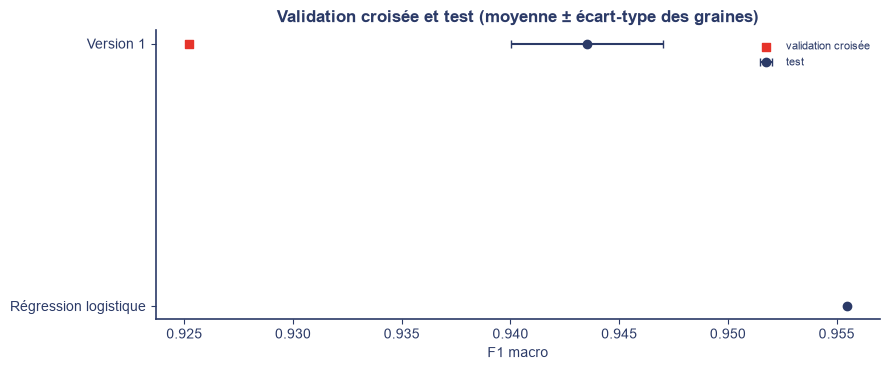

In [50]:
if CONFIRMER_TEST:
    fig, ax = plt.subplots(figsize=(9, 3.8))
    noms = [n.split(":")[0].strip() if ":" in n else n for n in res_test["configuration"]]
    y = np.arange(len(res_test))[::-1]
    ax.errorbar(res_test["test_f1"], y, xerr=res_test["test_f1_std"].fillna(0), fmt="o", color=BLEU, capsize=3, label="test")
    ax.scatter(res_test["f1_cv"], y, marker="s", color=ROUGE, label="validation croisée")
    ax.set_yticks(y); ax.set_yticklabels(noms); ax.set_xlabel("F1 macro")
    ax.set_title("Validation croisée et test (moyenne ± écart-type des graines)")
    ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()


### Matrices de confusion et rapport par classe

Pour chaque version, on affiche le modèle de graine 0 (graine choisie d'avance, pas la meilleure sur le test).

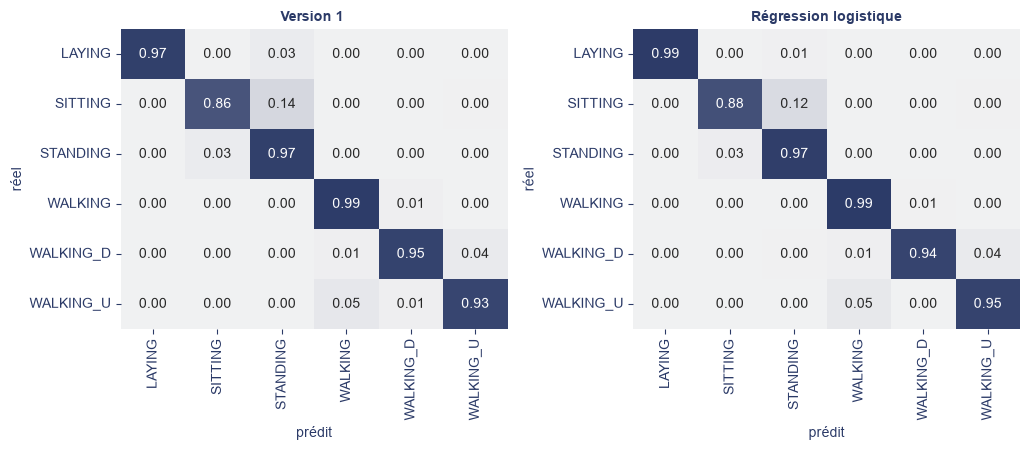


Version 1 : 1 couche (64), sans régularisation
                    precision    recall  f1-score   support

            LAYING      0.998     0.968     0.983       537
           SITTING      0.961     0.855     0.905       491
          STANDING      0.858     0.968     0.910       532
           WALKING      0.942     0.986     0.964       496
WALKING_DOWNSTAIRS      0.971     0.952     0.962       420
  WALKING_UPSTAIRS      0.961     0.934     0.947       471

          accuracy                          0.945      2947
         macro avg      0.949     0.944     0.945      2947
      weighted avg      0.947     0.945     0.945      2947


Régression logistique
                    precision    recall  f1-score   support

            LAYING      0.998     0.991     0.994       537
           SITTING      0.968     0.876     0.920       491
          STANDING      0.889     0.974     0.929       532
           WALKING      0.944     0.994     0.969       496
WALKING_DOWNSTAIRS      0

In [51]:
if CONFIRMER_TEST:
    a_montrer = [c["nom"] for c in CONFIGS if c["version"] == 1] + ["Régression logistique"]
    fig, ax = plt.subplots(1, len(a_montrer), figsize=(5.2 * len(a_montrer), 4.6))
    for a, nom in zip(np.atleast_1d(ax), a_montrer):
        cm = confusion_matrix(y_test, preds_seed0[nom], normalize="true")
        sns.heatmap(cm, annot=True, fmt=".2f", cmap=cmap_bleu, cbar=False, ax=a, vmin=0, vmax=1,
                    xticklabels=[c[:9] for c in classes], yticklabels=[c[:9] for c in classes])
        a.set_title(nom.split(":")[0] if ":" in nom else nom, fontsize=10)
        a.set_xlabel("prédit"); a.set_ylabel("réel")
    plt.tight_layout(); plt.show()
    for nom in a_montrer:
        print("\n" + nom)
        print(classification_report(y_test, preds_seed0[nom], target_names=classes, digits=3))


bilan de cette partie

- **Test contre validation croisée** : le F1 de test vaut accuracy 0,9435 ± 0,0033, soit 0,018 de plus que le F1 de validation croisée (0,9252). L'écart est positif et reste bien inférieur à l'écart-type entre partitions de volontaires (0,055) : il s'explique par la variabilité entre personnes (les 9 volontaires du test sont plus faciles, et le modèle final est entraîné sur 21 volontaires au lieu de 16), pas par une fuite de données.

- **Comparaison avec la régression logistique** : elle fait mieux que la Version 1 (F1 0,9555 contre 0,9435), et elle est meilleure sur chacune des six classes.

- **Erreurs principales** : les confusions se concentrent sur les deux postures statiques. Sur le test, 14 % des fenêtres SITTING sont classées STANDING et 3 % des STANDING sont classées SITTING ; sur la validation, c'était l'inverse (17 % de STANDING classées SITTING). Le sens de l'erreur dépend donc des volontaires, mais la paire SITTING/STANDING reste la plus difficile pour le MLP comme pour la régression logistique. Viennent ensuite les confusions entre marches (WALKING_UPSTAIRS prédite WALKING dans 5 % des cas, WALKING_DOWNSTAIRS prédite WALKING_UPSTAIRS dans 4 %).

-> assis et debout sont deux postures immobiles dont les signaux d'accélération sont presque identiques (la gravité pointe dans la même direction, seule l'inclinaison du buste et la position du téléphone diffèrent légèrement d'une personne à l'autre). LAYING est au contraire bien séparée, car la gravité change d'axe. Les trois marches ont des signaux dynamiques voisins, d'où les confusions entre elles.
